In [1]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('eurecom-aml-2021-challenge-2')

print("Path to competition files:", path)

Path to competition files: /kaggle/input/competitions/eurecom-aml-2021-challenge-2


In [2]:

import os
from pathlib import Path

# Update this path if your Kaggle dataset is mounted elsewhere
ROOT = Path("/kaggle/input/competitions/eurecom-aml-2021-challenge-2/refuge_data/refuge_data")

def count_files(folder):
    if not folder.exists():
        return 0
    return sum(1 for p in folder.rglob("*") if p.is_file())

print("=" * 65)
print("REFUGE DATASET FILE COUNTS")
print("=" * 65)

for split in ["train", "val", "test"]:
    split_dir = ROOT / split
    print(f"\n{split.upper()}")

    if not split_dir.exists():
        print(f"  Folder not found: {split_dir}")
        continue

    for subfolder in ["images", "gts", "illustrations"]:
        folder = split_dir / subfolder
        if folder.exists():
            print(f"  {subfolder:15s}: {count_files(folder)} files")

    print(f"  {'Total':15s}: {count_files(split_dir)} files")

print("\n" + "=" * 65)
print(f"TOTAL FILES: {count_files(ROOT)}")
print("=" * 65)


REFUGE DATASET FILE COUNTS

TRAIN
  images         : 400 files
  gts            : 400 files
  illustrations  : 400 files
  Total          : 1201 files

VAL
  images         : 400 files
  gts            : 400 files
  Total          : 801 files

TEST
  images         : 400 files
  gts            : 400 files
  Total          : 801 files

TOTAL FILES: 2803


In [3]:

import os
import json
import shutil
from pathlib import Path

# Existing REFUGE dataset
SRC = Path(
    "/kaggle/input/competitions/eurecom-aml-2021-challenge-2/"
    "refuge_data/refuge_data"
)

# New dataset with the required folder structure
DST = Path("/kaggle/working/refuge_split")

splits = ["train", "val", "test"]
subfolders = ["images", "gts", "illustrations"]

if not SRC.exists():
    raise FileNotFoundError(f"Dataset not found: {SRC}")

for split in splits:
    src_split = SRC / split
    dst_split = DST / split

    if not src_split.exists():
        print(f"WARNING: Missing split: {src_split}")
        continue

    dst_split.mkdir(parents=True, exist_ok=True)

    # Copy available subfolders
    for sub in subfolders:
        src_sub = src_split / sub
        dst_sub = dst_split / sub

        if src_sub.exists():
            shutil.copytree(src_sub, dst_sub, dirs_exist_ok=True)

    # Copy the split's index file
    index_file = src_split / "index.json"
    if index_file.exists():
        shutil.copy2(index_file, dst_split / "index.json")

print("Dataset structure created at:", DST)

# Verify the resulting structure
for split in splits:
    split_dir = DST / split
    if not split_dir.exists():
        continue

    print(f"\n{split.upper()}")
    for sub in subfolders:
        folder = split_dir / sub
        if folder.exists():
            n = sum(1 for p in folder.rglob("*") if p.is_file())
            print(f"  {sub}: {n} files")

    index_file = split_dir / "index.json"
    print("  index.json:", index_file.exists())


Dataset structure created at: /kaggle/working/refuge_split

TRAIN
  images: 400 files
  gts: 400 files
  illustrations: 400 files
  index.json: True

VAL
  images: 400 files
  gts: 400 files
  index.json: True

TEST
  images: 400 files
  gts: 400 files
  index.json: True


In [4]:

import json
import random
import shutil
from pathlib import Path

# Existing dataset
SRC = Path("/kaggle/working/refuge_split")

# New dataset matching the paper's split counts
DST = Path("/kaggle/working/refuge_paper_split")

SEED = 42
SPLIT_COUNTS = {"train": 540, "val": 60, "test": 600}
IMAGE_EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

# --------------------------------------------------
# 1. Collect images and masks from all existing splits
# --------------------------------------------------
image_map = {}
mask_map = {}

for split in ["train", "val", "test"]:
    img_dir = SRC / split / "images"
    gt_dir = SRC / split / "gts"

    if not img_dir.exists() or not gt_dir.exists():
        raise FileNotFoundError(
            f"Missing images or gts folder in {SRC / split}"
        )

    for p in img_dir.rglob("*"):
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
            if p.stem in image_map:
                raise ValueError(f"Duplicate image stem: {p.stem}")
            image_map[p.stem] = p

    for p in gt_dir.rglob("*"):
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
            if p.stem in mask_map:
                raise ValueError(f"Duplicate mask stem: {p.stem}")
            mask_map[p.stem] = p

image_ids = set(image_map)
mask_ids = set(mask_map)

print("Images found:", len(image_ids))
print("Masks found:", len(mask_ids))
print("Images without masks:", len(image_ids - mask_ids))
print("Masks without images:", len(mask_ids - image_ids))

if image_ids != mask_ids:
    raise ValueError(
        "Image-mask filenames do not match by stem. "
        "Inspect the unmatched filenames before splitting."
    )

pairs = [(image_map[k], mask_map[k], k) for k in sorted(image_ids)]

expected = sum(SPLIT_COUNTS.values())
if len(pairs) != expected:
    raise ValueError(
        f"Expected {expected} matched pairs, but found {len(pairs)}. "
        "Check the source dataset before proceeding."
    )

# --------------------------------------------------
# 2. Shuffle paired images and masks together
# --------------------------------------------------
random.Random(SEED).shuffle(pairs)

# --------------------------------------------------
# 3. Create train/val/test folders and copy pairs
# --------------------------------------------------
if DST.exists():
    shutil.rmtree(DST)

DST.mkdir(parents=True, exist_ok=True)

start = 0

for split, count in SPLIT_COUNTS.items():
    subset = pairs[start:start + count]
    start += count

    img_out = DST / split / "images"
    gt_out = DST / split / "gts"
    img_out.mkdir(parents=True, exist_ok=True)
    gt_out.mkdir(parents=True, exist_ok=True)

    records = []

    for image_path, mask_path, image_id in subset:
        shutil.copy2(image_path, img_out / image_path.name)
        shutil.copy2(mask_path, gt_out / mask_path.name)

        records.append({
            "id": image_id,
            "image": f"images/{image_path.name}",
            "mask": f"gts/{mask_path.name}"
        })

    with open(DST / split / "index.json", "w") as f:
        json.dump(records, f, indent=2)

    print(f"{split.upper():5s}: {len(records)} images, "
          f"{len(records)} masks")

print("\nNew dataset:", DST)
print("Expected counts:", SPLIT_COUNTS)


Images found: 1200
Masks found: 1200
Images without masks: 0
Masks without images: 0
TRAIN: 540 images, 540 masks
VAL  : 60 images, 60 masks
TEST : 600 images, 600 masks

New dataset: /kaggle/working/refuge_paper_split
Expected counts: {'train': 540, 'val': 60, 'test': 600}


In [5]:

import os, re, math, random, time
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models

# ----------------------------------------------------------------------------
# CONFIG
# ----------------------------------------------------------------------------
CFG = dict(
    img_size=256,          # must be divisible by 32
    batch_size=16,
    epochs=60,
    lr_backbone=3e-4,
    lr_head=1e-3,
    lr_quantum=1e-2,
    weight_decay=1e-4,
    n_qubits=4,
    n_vqc_layers=3,
    n_fuzzy_mf=3,          # membership functions per qubit -> 3^4 = 81 fuzzy rules
    fpn_channels=64,
    num_classes=3,
    pretrained=True,
    seed=42,
    num_workers=2,
    smoke_test=False,      # True = only check the model on random data
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."


def seed_everything(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)


# ----------------------------------------------------------------------------
# DATA DISCOVERY (robust to different folder layouts)
# ----------------------------------------------------------------------------
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
MASK_KEYS = ("mask", "gt", "label", "annot", "seg", "ground")


def print_tree(root, max_files=6):
    for dp, dn, fn in os.walk(root):
        depth = dp[len(root):].count(os.sep)
        if depth > 3:
            continue
        print("  " * depth + os.path.basename(dp) + "/")
        for f in sorted(fn)[:max_files]:
            print("  " * (depth + 1) + f)
        if len(fn) > max_files:
            print("  " * (depth + 1) + f"... (+{len(fn) - max_files} files)")


def find_split_dirs(root):
    cands = [dp for dp, dn, _ in os.walk(root) if any(d.lower() == "train" for d in dn)]
    if not cands:
        print_tree(root)
        raise FileNotFoundError("No 'train' folder found under dataset path.")
    base = sorted(cands, key=lambda p: p.count(os.sep))[0]
    aliases = {"train": ("train", "training"),
               "val": ("val", "valid", "validation"),
               "test": ("test", "testing")}
    out = {}
    for k, al in aliases.items():
        for d in os.listdir(base):
            full = os.path.join(base, d)
            if d.lower() in al and os.path.isdir(full):
                out[k] = full
                break
    return out


def is_mask_path(rel):
    parts = rel.lower().replace("\\", "/").split("/")
    return any(k in p for p in parts for k in MASK_KEYS)


def norm_stem(fn):
    s = os.path.splitext(fn)[0].lower()
    return re.sub(r"[_\-]?(mask|gt|seg|segmentation|label|annotation|annot)$", "", s)



def collect_pairs(split_dir):
    split_dir = Path(split_dir)
    index_file = split_dir / "index.json"

    if not index_file.exists():
        raise FileNotFoundError(f"Missing index file: {index_file}")

    with open(index_file, "r") as f:
        records = json.load(f)

    pairs = []
    missing = []

    for record in records:
        image_path = split_dir / record["image"]
        mask_path = split_dir / record["mask"]

        if not image_path.is_file() or not mask_path.is_file():
            missing.append((str(image_path), str(mask_path)))
            continue

        pairs.append((str(image_path), str(mask_path)))

    if missing:
        raise FileNotFoundError(
            f"{len(missing)} image-mask pairs have missing files. "
            f"First missing pair: {missing[0]}"
        )

    return pairs, len(pairs), len(pairs)



def map_mask(arr):
    """Convert raw REFUGE mask values to class ids {0:bg, 1:disc, 2:cup}."""
    if arr.max() > 2:                       # original REFUGE coding: 0=cup, 128=disc, 255=bg
        out = np.zeros(arr.shape, np.uint8)
        out[arr < 192] = 1
        out[arr < 64] = 2
        return out
    return arr.astype(np.uint8)             # already 0/1/2


def load_split(split_dir, size, name):
    pairs, n_i, n_m = collect_pairs(split_dir)
    print(f"[{name}] images found: {n_i}, masks found: {n_m}, matched pairs: {len(pairs)}")
    if not pairs:
        print_tree(split_dir)
        return None, None
    X = np.zeros((len(pairs), size, size, 3), np.uint8)
    Y = np.zeros((len(pairs), size, size), np.uint8)
    for i, (ip, mp) in enumerate(tqdm(pairs, desc=f"loading {name}")):
        X[i] = np.array(Image.open(ip).convert("RGB").resize((size, size), Image.BILINEAR))
        m = np.array(Image.open(mp))
        if m.ndim == 3:
            m = m[..., 0]
        m = np.array(Image.fromarray(m).resize((size, size), Image.NEAREST))
        Y[i] = map_mask(m)
    print(f"[{name}] class pixel fractions (bg/disc/cup):",
          np.round(np.bincount(Y.ravel(), minlength=3) / Y.size, 4))
    return X, Y


MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


class FundusDS(Dataset):
    def __init__(self, X, Y, train):
        self.X, self.Y, self.train = X, Y, train

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        img = torch.from_numpy(self.X[i]).permute(2, 0, 1).float() / 255.0
        msk = torch.from_numpy(self.Y[i]).long()
        if self.train:
            if random.random() < 0.5:
                img, msk = img.flip(2), msk.flip(1)
            if random.random() < 0.5:
                img, msk = img.flip(1), msk.flip(0)
            k = random.randint(0, 3)
            if k:
                img, msk = torch.rot90(img, k, (1, 2)), torch.rot90(msk, k, (0, 1))
            c, b = random.uniform(0.8, 1.2), random.uniform(-0.1, 0.1)
            img = ((img - 0.5) * c + 0.5 + b).clamp(0, 1)
        img = (img - MEAN) / STD
        return img, msk


# ----------------------------------------------------------------------------
# QUANTUM PART: differentiable state-vector VQC (real RY + CNOT ansatz)
# ----------------------------------------------------------------------------
def _ry_mat(theta):
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)


def _cnot_ring_inv_perm(n):
    inv = [0] * (2 ** n)
    for b in range(2 ** n):
        bits = [(b >> (n - 1 - w)) & 1 for w in range(n)]
        for c in range(n):
            t = (c + 1) % n
            if bits[c]:
                bits[t] ^= 1
        nb = sum(bit << (n - 1 - w) for w, bit in enumerate(bits))
        inv[nb] = b
    return torch.tensor(inv, dtype=torch.long)


class VQC(nn.Module):
    """Data re-uploading circuit: [RY(x) -> RY(w) -> CNOT ring] x L, output <Z_i> in [-1, 1]."""

    def __init__(self, n_qubits=4, n_layers=3):
        super().__init__()
        self.n, self.L = n_qubits, n_layers
        self.weights = nn.Parameter(torch.randn(n_layers, n_qubits) * 0.3)
        self.register_buffer("inv_perm", _cnot_ring_inv_perm(n_qubits))
        z = torch.tensor([[1 - 2 * ((b >> (n_qubits - 1 - w)) & 1) for w in range(n_qubits)]
                          for b in range(2 ** n_qubits)], dtype=torch.float32)
        self.register_buffer("zsign", z)

    def _apply_1q(self, state, mats, w):
        N = state.shape[0]
        s = state.view(N, 2 ** w, 2, 2 ** (self.n - w - 1))
        if mats.dim() == 3:
            s = torch.einsum("nij,najb->naib", mats, s)
        else:
            s = torch.einsum("ij,najb->naib", mats, s)
        return s.reshape(N, -1)

    def forward(self, x):                       # x: (N, n) angles
        N = x.shape[0]
        state = x.new_zeros(N, 2 ** self.n)
        state[:, 0] = 1.0
        for l in range(self.L):
            for w in range(self.n):
                state = self._apply_1q(state, _ry_mat(x[:, w]), w)       # data encoding
            for w in range(self.n):
                state = self._apply_1q(state, _ry_mat(self.weights[l, w]), w)  # trainable
            state = state[:, self.inv_perm]                              # entanglement
        return (state ** 2) @ self.zsign                                 # (N, n)


class QuantumFuzzy(nn.Module):
    """Gaussian fuzzy memberships over VQC outputs -> product t-norm rules -> TS consequent."""

    def __init__(self, n_in, n_mf, out_ch):
        super().__init__()
        self.n_in, self.n_mf = n_in, n_mf
        self.centers = nn.Parameter(torch.linspace(-1, 1, n_mf).repeat(n_in, 1))
        self.log_sigma = nn.Parameter(torch.full((n_in, n_mf), math.log(0.6)))
        self.consequent = nn.Linear(n_mf ** n_in, out_ch)

    def forward(self, q):                       # q: (N, n_in)
        d = q.unsqueeze(-1) - self.centers      # (N, n_in, K)
        mu = torch.exp(-0.5 * (d / self.log_sigma.exp()) ** 2)
        f = mu[:, 0]
        for i in range(1, self.n_in):
            f = (f.unsqueeze(-1) * mu[:, i].unsqueeze(1)).flatten(1)
        f = f / (f.sum(1, keepdim=True) + 1e-8)  # normalized rule strengths
        return self.consequent(f)


class QuantumFuzzyBlock(nn.Module):
    def __init__(self, in_ch, out_ch, n_qubits, n_layers, n_mf):
        super().__init__()
        self.nq = n_qubits
        self.to_angles = nn.Sequential(nn.Conv2d(in_ch, n_qubits, 1), nn.BatchNorm2d(n_qubits))
        self.vqc = VQC(n_qubits, n_layers)
        self.fuzzy = QuantumFuzzy(n_qubits, n_mf, out_ch)
        self.out_ch = out_ch

    def forward(self, x):
        B, _, H, W = x.shape
        a = torch.tanh(self.to_angles(x)) * math.pi                     # (B, Q, H, W)
        tok = a.permute(0, 2, 3, 1).reshape(-1, self.nq)
        with torch.autocast(device_type=x.device.type, enabled=False):  # quantum sim in fp32
            q = self.vqc(tok.float())
            y = self.fuzzy(q)
        return y.view(B, H, W, self.out_ch).permute(0, 3, 1, 2)


# ----------------------------------------------------------------------------
# CLASSICAL PARTS
# ----------------------------------------------------------------------------
def cbr(i, o, k=3):
    return nn.Sequential(nn.Conv2d(i, o, k, padding=k // 2, bias=False),
                         nn.BatchNorm2d(o), nn.ReLU(inplace=True))


class MobileNetV3SmallBackbone(nn.Module):
    out_channels = [16, 24, 48, 576]            # strides 4, 8, 16, 32

    def __init__(self, pretrained=True):
        super().__init__()
        try:
            w = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1 if pretrained else None
            m = models.mobilenet_v3_small(weights=w)
        except Exception as e:
            print("Could not load pretrained weights, using random init:", e)
            m = models.mobilenet_v3_small(weights=None)
        f = m.features
        self.s1, self.s2, self.s3, self.s4 = f[:2], f[2:4], f[4:9], f[9:]

    def forward(self, x):
        c1 = self.s1(x); c2 = self.s2(c1); c3 = self.s3(c2); c4 = self.s4(c3)
        return [c1, c2, c3, c4]


class MultiScaleFPN(nn.Module):
    def __init__(self, in_chs, ch):
        super().__init__()
        self.lat = nn.ModuleList([nn.Conv2d(c, ch, 1) for c in in_chs])
        self.smooth = nn.ModuleList([cbr(ch, ch, 3) for _ in in_chs])

    def forward(self, feats):
        lat = [l(f) for l, f in zip(self.lat, feats)]
        for i in range(len(lat) - 1, 0, -1):
            lat[i - 1] = lat[i - 1] + F.interpolate(lat[i], size=lat[i - 1].shape[-2:],
                                                    mode="bilinear", align_corners=False)
        return [s(l) for s, l in zip(self.smooth, lat)]


class QFuzzySegNet(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        ch = cfg["fpn_channels"]
        self.backbone = MobileNetV3SmallBackbone(cfg["pretrained"])
        self.fpn = MultiScaleFPN(self.backbone.out_channels, ch)
        self.ms_fuse = cbr(ch * 4, ch, 3)                       # fuse all scales at stride 4
        self.qf = QuantumFuzzyBlock(ch, ch, cfg["n_qubits"], cfg["n_vqc_layers"], cfg["n_fuzzy_mf"])
        self.qf_bn = nn.Sequential(nn.BatchNorm2d(ch), nn.ReLU(inplace=True))
        self.decoder = nn.Sequential(cbr(ch * 2, ch, 3), cbr(ch, ch, 3))
        self.head = nn.Conv2d(ch, cfg["num_classes"], 1)

    def forward(self, x):
        H, W = x.shape[-2:]
        p1, p2, p3, p4 = self.fpn(self.backbone(x))
        sz = p1.shape[-2:]
        up = lambda t: F.interpolate(t, size=sz, mode="bilinear", align_corners=False)
        fused = self.ms_fuse(torch.cat([p1, up(p2), up(p3), up(p4)], 1))   # multi-scale
        q = self.qf_bn(self.qf(p3))                                        # VQC + quantum fuzzy @ stride 16
        out = self.decoder(torch.cat([fused, up(q)], 1))
        logits = self.head(out)
        return F.interpolate(logits, size=(H, W), mode="bilinear", align_corners=False)


# ----------------------------------------------------------------------------
# LOSS / METRICS
# ----------------------------------------------------------------------------
def dice_loss(logits, target, n_cls=3, eps=1e-6):
    p = F.softmax(logits.float(), 1)
    oh = F.one_hot(target, n_cls).permute(0, 3, 1, 2).float()
    inter = (p * oh).sum((0, 2, 3))
    den = p.sum((0, 2, 3)) + oh.sum((0, 2, 3))
    return 1 - ((2 * inter + eps) / (den + eps)).mean()


def dice_iou(pm, tm):
    inter = (pm & tm).sum().item()
    s = pm.sum().item() + tm.sum().item()
    union = s - inter
    if s == 0:
        return 1.0, 1.0
    return 2 * inter / s, inter / max(union, 1)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    r = {"dice_disc": [], "dice_cup": [], "iou_disc": [], "iou_cup": []}
    for x, y in loader:
        pred = model(x.to(DEVICE)).argmax(1).cpu()
        for p, t in zip(pred, y):
            d, i = dice_iou(p >= 1, t >= 1); r["dice_disc"].append(d); r["iou_disc"].append(i)
            d, i = dice_iou(p == 2, t == 2); r["dice_cup"].append(d); r["iou_cup"].append(i)
    r = {k: float(np.mean(v)) for k, v in r.items()}
    r["mean_dice"] = (r["dice_disc"] + r["dice_cup"]) / 2
    return r


@torch.no_grad()
def save_predictions(model, X, Y, path, n=6):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    model.eval()
    idx = np.linspace(0, len(X) - 1, min(n, len(X))).astype(int)
    fig, ax = plt.subplots(3, len(idx), figsize=(3 * len(idx), 9))
    ax = np.atleast_2d(ax).reshape(3, -1)
    for j, i in enumerate(idx):
        img = (torch.from_numpy(X[i]).permute(2, 0, 1).float() / 255 - MEAN) / STD
        pred = model(img.unsqueeze(0).to(DEVICE)).argmax(1)[0].cpu().numpy()
        ax[0, j].imshow(X[i]); ax[1, j].imshow(Y[i], vmin=0, vmax=2, cmap="gray")
        ax[2, j].imshow(pred, vmin=0, vmax=2, cmap="gray")
        for k in range(3): ax[k, j].axis("off")
    ax[0, 0].set_title("image"); ax[1, 0].set_title("ground truth"); ax[2, 0].set_title("prediction")
    plt.tight_layout(); plt.savefig(path, dpi=110); plt.close()


# ----------------------------------------------------------------------------
# MAIN
# ----------------------------------------------------------------------------
def smoke_test():
    cfg = dict(CFG, pretrained=False)
    m = QFuzzySegNet(cfg).to(DEVICE)
    x = torch.randn(2, 3, cfg["img_size"], cfg["img_size"], device=DEVICE)
    y = torch.randint(0, 3, (2, cfg["img_size"], cfg["img_size"]), device=DEVICE)
    out = m(x)
    loss = F.cross_entropy(out, y) + dice_loss(out, y)
    loss.backward()
    print("output:", tuple(out.shape), "loss:", float(loss))
    print("VQC grad norm:", float(m.qf.vqc.weights.grad.norm()))
    print("params (M):", sum(p.numel() for p in m.parameters()) / 1e6)



def main():
    seed_everything(CFG["seed"])

    if CFG["smoke_test"]:
        smoke_test()
        return

    # --------------------------------------------------
    # DATASET: use the already-created paper-count split
    # --------------------------------------------------
    DATA_ROOT = Path("/kaggle/working/refuge_paper_split")

    expected_counts = {"train": 540, "val": 60, "test": 600}
    splits = {
        name: DATA_ROOT / name
        for name in expected_counts
    }

    if not DATA_ROOT.is_dir():
        raise FileNotFoundError(
            f"Dataset directory not found: {DATA_ROOT}\n"
            "Run your dataset preparation cell first."
        )

    for name, expected in expected_counts.items():
        folder = splits[name]
        index_file = folder / "index.json"

        if not folder.is_dir() or not index_file.is_file():
            raise FileNotFoundError(
                f"Missing split directory or index.json: {folder}"
            )

        with open(index_file, "r") as f:
            records = json.load(f)

        if len(records) != expected:
            raise ValueError(
                f"{name}: expected {expected} records, "
                f"found {len(records)} in {index_file}"
            )

        print(f"{name.upper():5s}: {len(records)} indexed image-mask pairs")

    # --------------------------------------------------
    # LOAD EXISTING SPLITS - NO ADDITIONAL RANDOM SPLIT
    # --------------------------------------------------
    S = CFG["img_size"]

    Xtr, Ytr = load_split(splits["train"], S, "train")
    Xva, Yva = load_split(splits["val"], S, "val")
    Xte, Yte = load_split(splits["test"], S, "test")

    if any(x is None for x in (Xtr, Xva, Xte)):
        raise RuntimeError("One or more splits contain no image-mask pairs.")

    if not (len(Xtr) == 540 and len(Xva) == 60 and len(Xte) == 600):
        raise RuntimeError(
            f"Unexpected loaded sizes: train={len(Xtr)}, "
            f"val={len(Xva)}, test={len(Xte)}"
        )

    print("\nLoaded dataset successfully:")
    print(f"Train: {len(Xtr)} images")
    print(f"Val:   {len(Xva)} images")
    print(f"Test:  {len(Xte)} images")

    # --------------------------------------------------
    # DATALOADERS
    # --------------------------------------------------
    def make_loader(X, Y, train):
        return DataLoader(
            FundusDS(X, Y, train),
            batch_size=CFG["batch_size"],
            shuffle=train,
            num_workers=CFG["num_workers"],
            pin_memory=(DEVICE.type == "cuda"),
            drop_last=train
        )

    tr_loader = make_loader(Xtr, Ytr, True)
    va_loader = make_loader(Xva, Yva, False)
    te_loader = make_loader(Xte, Yte, False)

    # --------------------------------------------------
    # MODEL
    # --------------------------------------------------
    model = QFuzzySegNet(CFG).to(DEVICE)

    print(
        "Trainable parameters (M):",
        sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
    )

    bb = list(model.backbone.parameters())
    qp = list(model.qf.vqc.parameters())
    excluded = {id(p) for p in bb + qp}
    rest = [p for p in model.parameters() if id(p) not in excluded]

    opt = torch.optim.AdamW(
        [
            {"params": bb, "lr": CFG["lr_backbone"]},
            {"params": qp, "lr": CFG["lr_quantum"], "weight_decay": 0},
            {"params": rest, "lr": CFG["lr_head"]},
        ],
        weight_decay=CFG["weight_decay"]
    )

    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt,
        max_lr=[
            CFG["lr_backbone"],
            CFG["lr_quantum"],
            CFG["lr_head"]
        ],
        total_steps=CFG["epochs"] * len(tr_loader),
        pct_start=0.1
    )

    use_amp = DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    best = -1.0
    ckpt = os.path.join(OUT_DIR, "best_qfuzzy_seg.pth")

    # --------------------------------------------------
    # TRAINING
    # --------------------------------------------------
    for ep in range(1, CFG["epochs"] + 1):
        model.train()
        t0 = time.time()
        total_loss = 0.0

        for x, y in tqdm(
            tr_loader,
            desc=f"Epoch {ep}/{CFG['epochs']}",
            leave=False
        ):
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)

            opt.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=use_amp
            ):
                out = model(x)

            loss = F.cross_entropy(out.float(), y) + dice_loss(out, y)

            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt)
            scaler.update()
            sched.step()

            total_loss += loss.item()

        val_metrics = evaluate(model, va_loader)

        print(
            f"Epoch {ep:02d} | "
            f"Loss {total_loss / max(1, len(tr_loader)):.4f} | "
            f"Val Disc Dice {val_metrics['dice_disc']:.4f} | "
            f"Val Cup Dice {val_metrics['dice_cup']:.4f} | "
            f"Val Mean Dice {val_metrics['mean_dice']:.4f} | "
            f"Time {time.time() - t0:.0f}s"
        )

        if val_metrics["mean_dice"] > best:
            best = val_metrics["mean_dice"]
            torch.save(model.state_dict(), ckpt)
            print(f"  Saved best checkpoint: {best:.4f}")

    # --------------------------------------------------
    # FINAL TEST: evaluate best validation checkpoint
    # --------------------------------------------------
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    print("\nBest validation metrics:", evaluate(model, va_loader))

    test_metrics = evaluate(model, te_loader)
    print("Final test metrics:", test_metrics)

    save_predictions(
        model,
        Xte,
        Yte,
        os.path.join(OUT_DIR, "test_predictions.png")
    )

    print("\nCheckpoint:", ckpt)
    print("Predictions:", os.path.join(OUT_DIR, "test_predictions.png"))


if __name__ == "__main__":
    main()





TRAIN: 540 indexed image-mask pairs
VAL  : 60 indexed image-mask pairs
TEST : 600 indexed image-mask pairs
[train] images found: 540, masks found: 540, matched pairs: 540


loading train:   0%|          | 0/540 [00:00<?, ?it/s]

[train] class pixel fractions (bg/disc/cup): [0.9833 0.0123 0.0043]
[val] images found: 60, masks found: 60, matched pairs: 60


loading val:   0%|          | 0/60 [00:00<?, ?it/s]

[val] class pixel fractions (bg/disc/cup): [0.9834 0.0122 0.0044]
[test] images found: 600, masks found: 600, matched pairs: 600


loading test:   0%|          | 0/600 [00:00<?, ?it/s]

... (128 outputs left out)

Epoch 59/60:   0%|          | 0/33 [00:00<?, ?it/s]

Epoch 59 | Loss 0.0572 | Val Disc Dice 0.9496 | Val Cup Dice 0.8605 | Val Mean Dice 0.9051 | Time 3s


Epoch 60/60:   0%|          | 0/33 [00:00<?, ?it/s]

Epoch 60 | Loss 0.0581 | Val Disc Dice 0.9498 | Val Cup Dice 0.8600 | Val Mean Dice 0.9049 | Time 3s

Best validation metrics: {'dice_disc': 0.9498172662991805, 'dice_cup': 0.863880360262017, 'iou_disc': 0.9054881846385853, 'iou_cup': 0.7684588759753753, 'mean_dice': 0.9068488132805987}
Final test metrics: {'dice_disc': 0.9523086386108237, 'dice_cup': 0.8726003132538498, 'iou_disc': 0.9099442259914038, 'iou_cup': 0.7793830308121329, 'mean_dice': 0.9124544759323368}

Checkpoint: /kaggle/working/best_qfuzzy_seg.pth
Predictions: /kaggle/working/test_predictions.png


[test] image-mask pairs: 600


loading test:   0%|          | 0/600 [00:00<?, ?it/s]

  raw mask values: [0, 128, 255]
  mapping: background=255, disc=128, cup=0
[test] class pixel fractions (OC/OD/BG): [0.0043 0.012  0.9837]
GT   encoding: background id = 2, cup id = 0
Pred encoding: background id = 0, cup id = 2
Saved: /kaggle/working/refuge_visualization.png | samples: [np.int64(551), np.int64(573), np.int64(93), np.int64(493), np.int64(358), np.int64(12)]


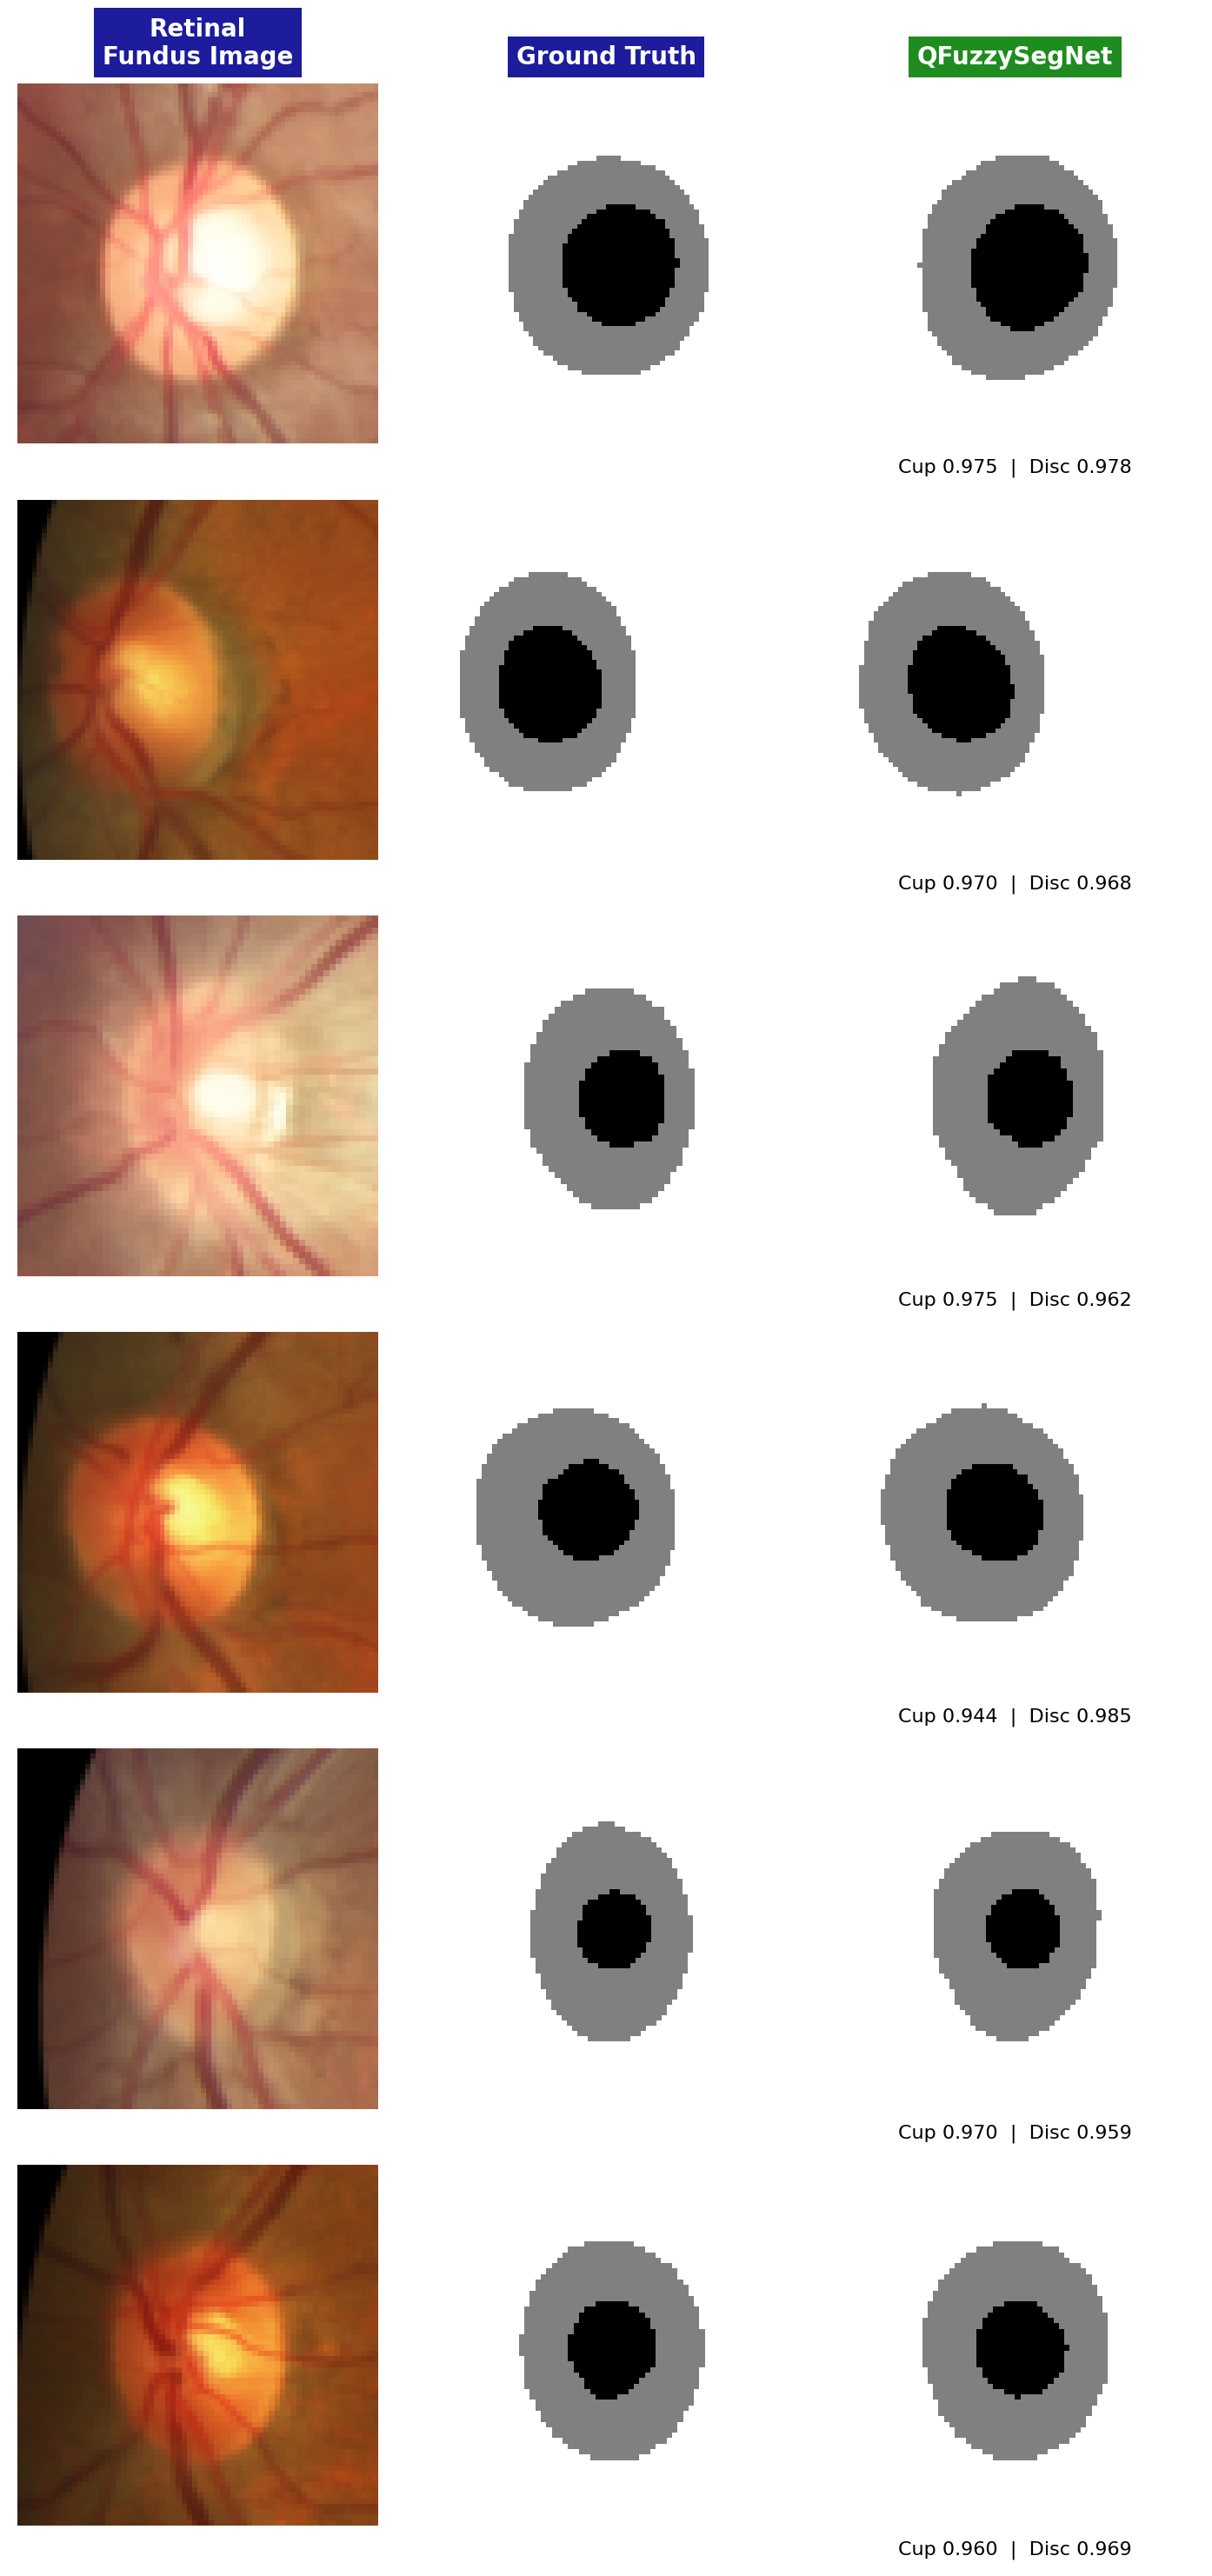

[np.int64(551),
 np.int64(573),
 np.int64(93),
 np.int64(493),
 np.int64(358),
 np.int64(12)]

In [18]:
# ----------------------------------------------------------------------------
# VISUALIZATION for the REFUGE script  (fundus image | ground truth | prediction)
#
# Paste this block into the REFUGE script ABOVE the "MAIN" section (or into a new
# notebook cell after the script has been run). It reuses: load_split, QFuzzySegNet,
# CFG, DEVICE, OUT_DIR, MEAN, STD from that script.
#
# Ground truth and prediction are ALWAYS drawn with the same colors:
#     black = cup, gray = disc, white = background
# The class ids of each label map are detected automatically (disc is always id 1;
# of ids {0, 2} the one covering more pixels is background, the other is cup), so
# the two panels cannot end up with opposite colors even if the ground truth and the
# model use different encodings.
# ----------------------------------------------------------------------------
import os
import json
from pathlib import Path          # the REFUGE script uses these but does not import them
import numpy as np
import torch
from matplotlib.colors import ListedColormap

MASK_CMAP = ListedColormap(["black", "#808080", "white"])     # display ids: 0=cup, 1=disc, 2=bg


def detect_ids(M):
    """Return (bg_id, cup_id) of a label array that uses class ids {0, 1, 2}."""
    return (0, 2) if (M == 0).sum() > (M == 2).sum() else (2, 0)


def to_display(M, ids):
    """Raw class ids -> display ids (cup=0, disc=1, bg=2) using detected (bg_id, cup_id)."""
    bg_id, cup_id = ids
    out = np.full(M.shape, 1, np.uint8)
    out[M == cup_id] = 0
    out[M == bg_id] = 2
    out[M == 1] = 1
    return out


@torch.no_grad()
def predict_all(model, X, batch_size=16, imagenet_norm=True):
    """uint8 images (N,H,W,3) -> raw predicted class ids (N,H,W)."""
    model.eval()
    out = []
    for i in range(0, len(X), batch_size):
        xb = torch.from_numpy(X[i:i + batch_size]).permute(0, 3, 1, 2).float() / 255.0
        if imagenet_norm:
            xb = (xb - MEAN) / STD                            # same normalization as training
        out.append(model(xb.to(DEVICE)).argmax(1).cpu().numpy().astype(np.uint8))
    return np.concatenate(out)


def _dice(pm, tm):
    s = pm.sum() + tm.sum()
    return 1.0 if s == 0 else 2.0 * (pm & tm).sum() / s


def _disc_crop(disp_mask, margin=0.35):
    """Square crop box (y0, y1, x0, x1) around the optic disc of a display-id mask."""
    H, W = disp_mask.shape
    ys, xs = np.where(disp_mask != 2)
    if len(ys) == 0:
        return 0, H, 0, W
    cy, cx = (ys.min() + ys.max()) / 2, (xs.min() + xs.max()) / 2
    side = max(ys.max() - ys.min(), xs.max() - xs.min()) * (1 + 2 * margin)
    side = int(min(max(side, 32), H, W))
    y0 = int(np.clip(cy - side / 2, 0, H - side))
    x0 = int(np.clip(cx - side / 2, 0, W - side))
    return y0, y0 + side, x0, x0 + side


def visualize_predictions(model, X, Y, path, idx=None, n=4, select="even",
                          crop_to_disc=True, margin=0.35, show_scores=True,
                          pred_title="Prediction", imagenet_norm=True, dpi=200, seed=0):
    """
    idx           : explicit list of sample indices (overrides n / select)
    n             : number of rows
    select        : "even" | "random" | "best" | "worst"  (best/worst by mean disc/cup Dice)
    crop_to_disc  : crop all three panels around the ground-truth disc (display only)
    imagenet_norm : True for a model trained by the original REFUGE script (ImageNet mean/std).
                    Set False for a model trained with the paper-protocol script ([0,1] only).
    """
    import matplotlib.pyplot as plt

    P = predict_all(model, X, imagenet_norm=imagenet_norm)

    # --- bring GT and prediction to the same display convention ------------------
    gt_ids, pr_ids = detect_ids(Y), detect_ids(P)
    print(f"GT   encoding: background id = {gt_ids[0]}, cup id = {gt_ids[1]}")
    print(f"Pred encoding: background id = {pr_ids[0]}, cup id = {pr_ids[1]}")
    if gt_ids != pr_ids:
        print("WARNING: ground truth and predictions use OPPOSITE class ids. The figure is "
              "corrected, but evaluate() compares raw ids and will give wrong Dice/IoU -- "
              "load the data with the same encoding the model was trained with.")
    Yd = np.stack([to_display(m, gt_ids) for m in Y])
    Pd = np.stack([to_display(m, pr_ids) for m in P])

    dsc_cup = np.array([_dice(Pd[i] == 0, Yd[i] == 0) for i in range(len(X))])
    dsc_disc = np.array([_dice(Pd[i] <= 1, Yd[i] <= 1) for i in range(len(X))])   # disc incl. cup
    mean_dsc = (dsc_disc + dsc_cup) / 2

    if idx is None:
        n = min(n, len(X))
        if select == "even":
            idx = np.linspace(0, len(X) - 1, n).astype(int)
        elif select == "random":
            idx = np.random.RandomState(seed).choice(len(X), n, replace=False)
        elif select == "best":
            idx = np.argsort(-mean_dsc)[:n]
        elif select == "worst":
            idx = np.argsort(mean_dsc)[:n]
        else:
            raise ValueError(select)
    idx = list(idx)
    n = len(idx)

    fig, axes = plt.subplots(n, 3, figsize=(7.2, 2.4 * n + 0.5), squeeze=False)
    heads = [("Retinal\nFundus Image", "#1c1c9c"),
             ("Ground Truth", "#1c1c9c"),
             (pred_title, "#1e8c1e")]

    for r, i in enumerate(idx):
        if crop_to_disc:
            y0, y1, x0, x1 = _disc_crop(Yd[i], margin)
        else:
            y0, y1, x0, x1 = 0, Yd[i].shape[0], 0, Yd[i].shape[1]
        panels = [X[i][y0:y1, x0:x1], Yd[i][y0:y1, x0:x1], Pd[i][y0:y1, x0:x1]]
        for c, panel in enumerate(panels):
            ax = axes[r, c]
            if c == 0:
                ax.imshow(panel)
            else:
                ax.imshow(panel, cmap=MASK_CMAP, vmin=0, vmax=2, interpolation="nearest")
            ax.axis("off")
            if r == 0:
                ax.set_title(heads[c][0], color="white", fontsize=10, fontweight="bold",
                             pad=8, bbox=dict(boxstyle="square,pad=0.35",
                                              fc=heads[c][1], ec="none"))
        if show_scores:
            axes[r, 2].text(0.5, -0.04,
                            f"Cup {dsc_cup[i]:.3f}  |  Disc {dsc_disc[i]:.3f}",
                            transform=axes[r, 2].transAxes, ha="center", va="top", fontsize=8)

    plt.tight_layout()
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    print("Saved:", path, "| samples:", idx)
    try:                                   # show inline in notebooks
        from IPython.display import display, Image as IPImage
        display(IPImage(filename=path))
    except Exception:
        pass
    return idx


def run_refuge_visualization(n=4, select="even", pred_title="QFuzzySegNet", imagenet_norm=True):
    """Load the best REFUGE checkpoint and visualize predictions on the REFUGE test split."""
    test_dir = Path("/kaggle/working/refuge_paper_split") / "test"
    ckpt = os.path.join(OUT_DIR, "best_qfuzzy_seg.pth")
    Xte, Yte = load_split(test_dir, CFG["img_size"], "test")

    model = QFuzzySegNet(dict(CFG, pretrained=False)).to(DEVICE)   # weights come from ckpt
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return visualize_predictions(
        model, Xte, Yte, os.path.join(OUT_DIR, "refuge_visualization.png"),
        n=n, select=select, pred_title=pred_title, imagenet_norm=imagenet_norm)


# Usage:
#   run_refuge_visualization()                      # 4 evenly spaced test samples
run_refuge_visualization(n=6, select="best")      # 6 best cases
#   run_refuge_visualization(n=6, select="worst")   # 6 worst cases
#   run_refuge_visualization(imagenet_norm=False)   # model trained with the paper-protocol script

In [6]:

# ============================================================
# MODEL COMPLEXITY: PARAMETERS + FLOPs
# Run after defining QFuzzySegNet and CFG
# ============================================================
!pip install fvcore
import torch
import torch.nn as nn

def count_model_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)

    print("\n" + "=" * 55)
    print("MODEL PARAMETERS")
    print("=" * 55)
    print(f"Total parameters:     {total:,} ({total / 1e6:.4f} M)")
    print(f"Trainable parameters: {trainable:,} ({trainable / 1e6:.4f} M)")
    print(f"Non-trainable params: {total - trainable:,}")
    return total, trainable


def count_flops(model, img_size=256):
    # Preferred: fvcore for standard PyTorch operator FLOPs
    try:
        from fvcore.nn import FlopCountAnalysis

        model.eval()
        device = next(model.parameters()).device
        x = torch.randn(1, 3, img_size, img_size, device=device)

        with torch.no_grad():
            analysis = FlopCountAnalysis(model, x)
            analysis.unsupported_ops_warnings(False)
            analysis.uncalled_modules_warnings(False)
            flops = analysis.total()

        print("\n" + "=" * 55)
        print("MODEL COMPUTATION")
        print("=" * 55)
        print(f"Input size: {img_size} x {img_size}")
        print(f"FLOPs: {flops:,} ({flops / 1e9:.4f} GFLOPs)")
        print(f"Approx. MACs: {flops / 2:,.0f} ({flops / 2e9:.4f} GMACs)")
        print("Note: Custom quantum/state-vector operations may be unsupported.")
        print("Inspect fvcore's operator analysis before interpreting FLOPs.")
        return flops

    except ImportError:
        print("\nInstall fvcore first using:")
        print("!pip install fvcore")
        return None


# Build the model using your existing configuration
complexity_model = QFuzzySegNet(CFG).to(DEVICE)

total_params, trainable_params = count_model_params(complexity_model)
flops = count_flops(complexity_model, CFG["img_size"])


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for fvcore: filename=fvcore-0.1.5.post20221221-py3-none-any.whl size=61447 sha256=96c60b017e226e34968c70ab48afb46b7afeeebef33cb9d29a82dd645b2ea41c
  Stored in directory: /root/.cache/pip/wheels/6b/1b/9a/9f4843148961a522f56dbeaa5543071ac2389d9a079ec724ab
  Created wheel for iopath: filename=iopath-0.1.10-py3-none-any.whl size=31598 sha256=e35a311624634433bb588c72ee92f878f2eab790560b076edc36490eae2782f0
  Stored in directory: /root/.cache/pip/wheels/cd/c4/19/776124f304c8d9cb940cb164ec2ad635b42d9d1cf03217506d
Successfully built fvcore iopath
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [fvcore]2m3/4 [fvcore]

MODEL PARAMETERS
Total parameters:     1,382,035 (1.3820 M)
Trainable parameters: 1,382,035 (1.38

In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("baivabmukherjee/fundus-images")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/baivabmukherjee/fundus-images


In [8]:

import os, re, json, random, shutil
from pathlib import Path
from collections import defaultdict

# ============================================================
# ORIGA DATASET SPLIT: 450 TRAIN / 50 VAL / 150 TEST
# ============================================================
SRC = Path("/kaggle/input/datasets/baivabmukherjee/fundus-images/ORIGA")
DST = Path("/kaggle/working/ORIGA_split")

SEED = 42
SPLIT_COUNTS = {"train": 450, "val": 50, "test": 150}
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

# Directory/file names that indicate ground-truth masks
MASK_KEYS = ("mask", "masks", "gt", "gts", "groundtruth",
             "ground_truth", "label", "labels", "segmentation")

assert SRC.exists(), f"Dataset not found: {SRC}"

def is_mask_file(path):
    parts = [p.lower() for p in path.parts]
    stem = path.stem.lower()
    return (
        any(k in part for part in parts[:-1] for k in MASK_KEYS)
        or re.search(r"[_\- ](mask|gt|label|segmentation|annotation)$", stem) is not None
    )

def normalize_stem(path):
    stem = path.stem.lower()
    return re.sub(
        r"[_\- ]?(mask|gt|label|segmentation|annotation)$", "", stem
    )

# ------------------------------------------------------------
# 1. Collect images and masks from existing train/test folders
# ------------------------------------------------------------
image_map = defaultdict(list)
mask_map = defaultdict(list)

for split in ["train", "test", "val", "validation"]:
    folder = SRC / split
    if not folder.exists():
        continue

    for p in folder.rglob("*"):
        if not p.is_file() or p.suffix.lower() not in IMG_EXT:
            continue

        key = normalize_stem(p)
        if is_mask_file(p):
            mask_map[key].append(p)
        else:
            image_map[key].append(p)

# Only pair images with masks having matching normalized filenames
pairs = []
used_images, used_masks = set(), set()

for key in sorted(set(image_map) & set(mask_map)):
    if len(image_map[key]) != 1 or len(mask_map[key]) != 1:
        print(f"Skipping ambiguous pair: {key}")
        continue

    ip, mp = image_map[key][0], mask_map[key][0]
    pairs.append((ip, mp, key))
    used_images.add(ip)
    used_masks.add(mp)

print("Dataset root:", SRC)
print("Matched image-mask pairs:", len(pairs))
print("Unmatched images:", sum(len(v) for k, v in image_map.items()
                                if not all(p in used_images for p in v)))
print("Unmatched masks:", sum(len(v) for k, v in mask_map.items()
                              if not all(p in used_masks for p in v)))

expected = sum(SPLIT_COUNTS.values())
if len(pairs) < expected:
    print("\nTop-level dataset structure:")
    for p in sorted(SRC.iterdir()):
        print(" ", p.name, "(directory)" if p.is_dir() else "(file)")

    raise RuntimeError(
        f"Need {expected} matched image-mask pairs, but found {len(pairs)}. "
        "Check the ORIGA folder structure and mask filenames before splitting."
    )

# ------------------------------------------------------------
# 2. Shuffle matched pairs together
# ------------------------------------------------------------
random.Random(SEED).shuffle(pairs)
pairs = pairs[:expected]

# ------------------------------------------------------------
# 3. Create a clean output directory
# ------------------------------------------------------------
if DST.exists():
    shutil.rmtree(DST)

DST.mkdir(parents=True, exist_ok=True)

start = 0

for split, count in SPLIT_COUNTS.items():
    subset = pairs[start:start + count]
    start += count

    img_out = DST / split / "images"
    gt_out = DST / split / "gts"
    img_out.mkdir(parents=True, exist_ok=True)
    gt_out.mkdir(parents=True, exist_ok=True)

    records = []

    for ip, mp, key in subset:
        # Use a common ID to guarantee image-mask correspondence
        image_name = key + ip.suffix.lower()
        mask_name = key + mp.suffix.lower()

        shutil.copy2(ip, img_out / image_name)
        shutil.copy2(mp, gt_out / mask_name)

        records.append({
            "id": key,
            "image": f"images/{image_name}",
            "mask": f"gts/{mask_name}"
        })

    with open(DST / split / "index.json", "w") as f:
        json.dump(records, f, indent=2)

    print(f"{split.upper():5s}: {len(records)} images, "
          f"{len(records)} masks")

print("\nNew dataset saved to:", DST)
print("Expected split:", SPLIT_COUNTS)


Dataset root: /kaggle/input/datasets/baivabmukherjee/fundus-images/ORIGA
Matched image-mask pairs: 650
Unmatched images: 0
Unmatched masks: 0
TRAIN: 450 images, 450 masks
VAL  : 50 images, 50 masks
TEST : 150 images, 150 masks

New dataset saved to: /kaggle/working/ORIGA_split
Expected split: {'train': 450, 'val': 50, 'test': 150}


In [9]:
import os, math, random, time, json
from pathlib import Path
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models

# ----------------------------------------------------------------------------
# CONFIG  (experimental setup follows CSP-SegNet paper, ORIGA protocol)
#   - input 256x256, pixel values rescaled to [0, 1]   (Sec. 3.1)
#   - labels: 0 = OC (black), 1 = OD (gray), 2 = background (white)  (Sec. 3.1)
#   - Adam, lr = 0.001, batch size 16, 50 epochs on ORIGA (Sec. 3.3)
#   - split 450 / 50 / 150 (Table 1)
#   - best checkpoint chosen by validation IoU (Algorithm 1, step 6)
#   - loss: Dice (default) | IoU | Dice+IoU (Sec. 3.4, Eqs. 3-7)
#   - no data augmentation, no LR scheduler, no AMP, no grad clipping
# ----------------------------------------------------------------------------
CFG = dict(
    img_size=256,
    batch_size=16,
    epochs=50,
    lr=1e-3,
    loss="dice",           # "dice" | "iou" | "combined"
    n_qubits=4,
    n_vqc_layers=3,
    n_fuzzy_mf=3,
    fpn_channels=64,
    num_classes=3,
    pretrained=True,
    seed=42,
    num_workers=2,
    smoke_test=False,
)

# Class ids (paper encoding)
OC, OD, BG = 0, 1, 2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."


def seed_everything(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)


# ----------------------------------------------------------------------------
# DATA
# ----------------------------------------------------------------------------
def collect_pairs(split_dir):
    split_dir = Path(split_dir)
    index_file = split_dir / "index.json"
    if not index_file.exists():
        raise FileNotFoundError(f"Missing index file: {index_file}")
    with open(index_file, "r") as f:
        records = json.load(f)
    pairs, missing = [], []
    for r in records:
        ip, mp = split_dir / r["image"], split_dir / r["mask"]
        if not ip.is_file() or not mp.is_file():
            missing.append((str(ip), str(mp)))
            continue
        pairs.append((str(ip), str(mp)))
    if missing:
        raise FileNotFoundError(f"{len(missing)} pairs missing files. First: {missing[0]}")
    return pairs


def map_mask(arr):
    """Paper encoding: black (OC) -> 0, gray (OD) -> 1, white (background) -> 2.
    Handles 0/128/255-style grayscale masks. If the mask already holds class ids
    {0,1,2} it is assumed to already follow the paper encoding -- verify this
    against the printed class fractions."""
    if arr.max() > 2:
        out = np.full(arr.shape, BG, np.uint8)
        out[arr < 192] = OD
        out[arr < 64] = OC
        return out
    return arr.astype(np.uint8)


def load_split(split_dir, size, name):
    pairs = collect_pairs(split_dir)
    print(f"[{name}] image-mask pairs: {len(pairs)}")
    X = np.zeros((len(pairs), size, size, 3), np.uint8)
    Y = np.zeros((len(pairs), size, size), np.uint8)
    for i, (ip, mp) in enumerate(tqdm(pairs, desc=f"loading {name}")):
        X[i] = np.array(Image.open(ip).convert("RGB").resize((size, size), Image.BILINEAR))
        m = np.array(Image.open(mp))
        if m.ndim == 3:
            m = m[..., 0]
        m = np.array(Image.fromarray(m).resize((size, size), Image.NEAREST))
        Y[i] = map_mask(m)
    print(f"[{name}] class pixel fractions (OC/OD/BG):",
          np.round(np.bincount(Y.ravel(), minlength=3) / Y.size, 4))
    return X, Y


class FundusDS(Dataset):
    """Paper preprocessing only: resize (done at load) + rescale to [0, 1]. No augmentation."""

    def __init__(self, X, Y):
        self.X, self.Y = X, Y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        img = torch.from_numpy(self.X[i]).permute(2, 0, 1).float() / 255.0
        msk = torch.from_numpy(self.Y[i]).long()
        return img, msk


# ----------------------------------------------------------------------------
# QUANTUM PART (unchanged)
# ----------------------------------------------------------------------------
def _ry_mat(theta):
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)


def _cnot_ring_inv_perm(n):
    inv = [0] * (2 ** n)
    for b in range(2 ** n):
        bits = [(b >> (n - 1 - w)) & 1 for w in range(n)]
        for c in range(n):
            t = (c + 1) % n
            if bits[c]:
                bits[t] ^= 1
        nb = sum(bit << (n - 1 - w) for w, bit in enumerate(bits))
        inv[nb] = b
    return torch.tensor(inv, dtype=torch.long)


class VQC(nn.Module):
    def __init__(self, n_qubits=4, n_layers=3):
        super().__init__()
        self.n, self.L = n_qubits, n_layers
        self.weights = nn.Parameter(torch.randn(n_layers, n_qubits) * 0.3)
        self.register_buffer("inv_perm", _cnot_ring_inv_perm(n_qubits))
        z = torch.tensor([[1 - 2 * ((b >> (n_qubits - 1 - w)) & 1) for w in range(n_qubits)]
                          for b in range(2 ** n_qubits)], dtype=torch.float32)
        self.register_buffer("zsign", z)

    def _apply_1q(self, state, mats, w):
        N = state.shape[0]
        s = state.view(N, 2 ** w, 2, 2 ** (self.n - w - 1))
        if mats.dim() == 3:
            s = torch.einsum("nij,najb->naib", mats, s)
        else:
            s = torch.einsum("ij,najb->naib", mats, s)
        return s.reshape(N, -1)

    def forward(self, x):
        N = x.shape[0]
        state = x.new_zeros(N, 2 ** self.n)
        state[:, 0] = 1.0
        for l in range(self.L):
            for w in range(self.n):
                state = self._apply_1q(state, _ry_mat(x[:, w]), w)
            for w in range(self.n):
                state = self._apply_1q(state, _ry_mat(self.weights[l, w]), w)
            state = state[:, self.inv_perm]
        return (state ** 2) @ self.zsign


class QuantumFuzzy(nn.Module):
    def __init__(self, n_in, n_mf, out_ch):
        super().__init__()
        self.n_in, self.n_mf = n_in, n_mf
        self.centers = nn.Parameter(torch.linspace(-1, 1, n_mf).repeat(n_in, 1))
        self.log_sigma = nn.Parameter(torch.full((n_in, n_mf), math.log(0.6)))
        self.consequent = nn.Linear(n_mf ** n_in, out_ch)

    def forward(self, q):
        d = q.unsqueeze(-1) - self.centers
        mu = torch.exp(-0.5 * (d / self.log_sigma.exp()) ** 2)
        f = mu[:, 0]
        for i in range(1, self.n_in):
            f = (f.unsqueeze(-1) * mu[:, i].unsqueeze(1)).flatten(1)
        f = f / (f.sum(1, keepdim=True) + 1e-8)
        return self.consequent(f)


class QuantumFuzzyBlock(nn.Module):
    def __init__(self, in_ch, out_ch, n_qubits, n_layers, n_mf):
        super().__init__()
        self.nq = n_qubits
        self.to_angles = nn.Sequential(nn.Conv2d(in_ch, n_qubits, 1), nn.BatchNorm2d(n_qubits))
        self.vqc = VQC(n_qubits, n_layers)
        self.fuzzy = QuantumFuzzy(n_qubits, n_mf, out_ch)
        self.out_ch = out_ch

    def forward(self, x):
        B, _, H, W = x.shape
        a = torch.tanh(self.to_angles(x)) * math.pi
        tok = a.permute(0, 2, 3, 1).reshape(-1, self.nq)
        q = self.vqc(tok.float())
        y = self.fuzzy(q)
        return y.view(B, H, W, self.out_ch).permute(0, 3, 1, 2)


# ----------------------------------------------------------------------------
# CLASSICAL PARTS (unchanged)
# ----------------------------------------------------------------------------
def cbr(i, o, k=3):
    return nn.Sequential(nn.Conv2d(i, o, k, padding=k // 2, bias=False),
                         nn.BatchNorm2d(o), nn.ReLU(inplace=True))


class MobileNetV3SmallBackbone(nn.Module):
    out_channels = [16, 24, 48, 576]

    def __init__(self, pretrained=True):
        super().__init__()
        try:
            w = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1 if pretrained else None
            m = models.mobilenet_v3_small(weights=w)
        except Exception as e:
            print("Could not load pretrained weights, using random init:", e)
            m = models.mobilenet_v3_small(weights=None)
        f = m.features
        self.s1, self.s2, self.s3, self.s4 = f[:2], f[2:4], f[4:9], f[9:]

    def forward(self, x):
        c1 = self.s1(x); c2 = self.s2(c1); c3 = self.s3(c2); c4 = self.s4(c3)
        return [c1, c2, c3, c4]


class MultiScaleFPN(nn.Module):
    def __init__(self, in_chs, ch):
        super().__init__()
        self.lat = nn.ModuleList([nn.Conv2d(c, ch, 1) for c in in_chs])
        self.smooth = nn.ModuleList([cbr(ch, ch, 3) for _ in in_chs])

    def forward(self, feats):
        lat = [l(f) for l, f in zip(self.lat, feats)]
        for i in range(len(lat) - 1, 0, -1):
            lat[i - 1] = lat[i - 1] + F.interpolate(lat[i], size=lat[i - 1].shape[-2:],
                                                    mode="bilinear", align_corners=False)
        return [s(l) for s, l in zip(self.smooth, lat)]


class QFuzzySegNet(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        ch = cfg["fpn_channels"]
        self.backbone = MobileNetV3SmallBackbone(cfg["pretrained"])
        self.fpn = MultiScaleFPN(self.backbone.out_channels, ch)
        self.ms_fuse = cbr(ch * 4, ch, 3)
        self.qf = QuantumFuzzyBlock(ch, ch, cfg["n_qubits"], cfg["n_vqc_layers"], cfg["n_fuzzy_mf"])
        self.qf_bn = nn.Sequential(nn.BatchNorm2d(ch), nn.ReLU(inplace=True))
        self.decoder = nn.Sequential(cbr(ch * 2, ch, 3), cbr(ch, ch, 3))
        self.head = nn.Conv2d(ch, cfg["num_classes"], 1)

    def forward(self, x):
        H, W = x.shape[-2:]
        p1, p2, p3, p4 = self.fpn(self.backbone(x))
        sz = p1.shape[-2:]
        up = lambda t: F.interpolate(t, size=sz, mode="bilinear", align_corners=False)
        fused = self.ms_fuse(torch.cat([p1, up(p2), up(p3), up(p4)], 1))
        q = self.qf_bn(self.qf(p3))
        out = self.decoder(torch.cat([fused, up(q)], 1))
        logits = self.head(out)
        return F.interpolate(logits, size=(H, W), mode="bilinear", align_corners=False)


# ----------------------------------------------------------------------------
# LOSSES (paper Eqs. 3-7)
# ----------------------------------------------------------------------------
def _soft_onehot(logits, target, n_cls=3):
    p = F.softmax(logits.float(), 1)
    oh = F.one_hot(target, n_cls).permute(0, 3, 1, 2).float()
    return p, oh


def dice_loss(logits, target, n_cls=3):
    """Eq. 4: 1 - (sum p*q + 1) / (sum p + sum q + 1), summed over all pixels/classes."""
    p, oh = _soft_onehot(logits, target, n_cls)
    inter = (p * oh).sum()
    return 1 - (inter + 1.0) / (p.sum() + oh.sum() + 1.0)


def iou_loss(logits, target, n_cls=3, eps=1e-7):
    """Eq. 6: 1 - sum p*q / (sum p + sum q - sum p*q)."""
    p, oh = _soft_onehot(logits, target, n_cls)
    inter = (p * oh).sum()
    return 1 - inter / (p.sum() + oh.sum() - inter + eps)


def get_loss(name):
    if name == "dice":
        return dice_loss
    if name == "iou":
        return iou_loss
    if name == "combined":
        return lambda o, t: dice_loss(o, t) + iou_loss(o, t)   # Eq. 7
    raise ValueError(name)


# ----------------------------------------------------------------------------
# METRICS (paper Eqs. 8-11), per class OC / OD
# ----------------------------------------------------------------------------
def class_metrics(pm, tm):
    tp = (pm & tm).sum().item()
    fp = (pm & ~tm).sum().item()
    fn = (~pm & tm).sum().item()
    if tp + fp + fn == 0:
        return dict(p=1.0, r=1.0, dsc=1.0, iou=1.0)
    return dict(
        p=tp / (tp + fp) if tp + fp else 0.0,
        r=tp / (tp + fn) if tp + fn else 0.0,
        dsc=2 * tp / (2 * tp + fp + fn),
        iou=tp / (tp + fp + fn),
    )


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    acc = {c: {"p": [], "r": [], "dsc": [], "iou": []} for c in ("oc", "od")}
    for x, y in loader:
        pred = model(x.to(DEVICE)).argmax(1).cpu()
        for p, t in zip(pred, y):
            for name, cid in (("oc", OC), ("od", OD)):
                m = class_metrics(p == cid, t == cid)
                for k in m:
                    acc[name][k].append(m[k])
    r = {}
    for name in ("oc", "od"):
        r[f"dsc_{name}"] = float(np.mean(acc[name]["dsc"]))
        r[f"iou_{name}"] = float(np.mean(acc[name]["iou"]))
        r[f"precision_{name}"] = float(np.mean(acc[name]["p"]))
        r[f"recall_{name}"] = float(np.mean(acc[name]["r"]))
    r["precision"] = (r["precision_oc"] + r["precision_od"]) / 2
    r["recall"] = (r["recall_oc"] + r["recall_od"]) / 2
    r["mean_dsc"] = (r["dsc_oc"] + r["dsc_od"]) / 2
    r["mean_iou"] = (r["iou_oc"] + r["iou_od"]) / 2      # used for checkpointing
    return r


@torch.no_grad()
def save_predictions(model, X, Y, path, n=6):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    model.eval()
    idx = np.linspace(0, len(X) - 1, min(n, len(X))).astype(int)
    fig, ax = plt.subplots(3, len(idx), figsize=(3 * len(idx), 9))
    ax = np.atleast_2d(ax).reshape(3, -1)
    for j, i in enumerate(idx):
        img = torch.from_numpy(X[i]).permute(2, 0, 1).float() / 255
        pred = model(img.unsqueeze(0).to(DEVICE)).argmax(1)[0].cpu().numpy()
        ax[0, j].imshow(X[i]); ax[1, j].imshow(Y[i], vmin=0, vmax=2, cmap="gray")
        ax[2, j].imshow(pred, vmin=0, vmax=2, cmap="gray")
        for k in range(3): ax[k, j].axis("off")
    ax[0, 0].set_title("image"); ax[1, 0].set_title("ground truth"); ax[2, 0].set_title("prediction")
    plt.tight_layout(); plt.savefig(path, dpi=110); plt.close()


# ----------------------------------------------------------------------------
# MAIN
# ----------------------------------------------------------------------------
def smoke_test():
    cfg = dict(CFG, pretrained=False)
    m = QFuzzySegNet(cfg).to(DEVICE)
    s = cfg["img_size"]
    x = torch.rand(2, 3, s, s, device=DEVICE)
    y = torch.randint(0, 3, (2, s, s), device=DEVICE)
    out = m(x)
    loss = get_loss(cfg["loss"])(out, y)
    loss.backward()
    print("output:", tuple(out.shape), "loss:", float(loss))
    print("VQC grad norm:", float(m.qf.vqc.weights.grad.norm()))
    print("params (M):", sum(p.numel() for p in m.parameters()) / 1e6)


def main():
    seed_everything(CFG["seed"])
    if CFG["smoke_test"]:
        smoke_test()
        return

    DATA_ROOT = Path("/kaggle/working/ORIGA_split")
    expected = {"train": 450, "val": 50, "test": 150}      # Table 1
    splits = {k: DATA_ROOT / k for k in expected}

    if not DATA_ROOT.is_dir():
        raise FileNotFoundError(f"Dataset directory not found: {DATA_ROOT}")
    for name, n in expected.items():
        idx = splits[name] / "index.json"
        if not idx.is_file():
            raise FileNotFoundError(f"Missing {idx}")
        with open(idx) as f:
            cnt = len(json.load(f))
        if cnt != n:
            raise ValueError(f"{name}: expected {n} records, found {cnt}")
        print(f"{name.upper():5s}: {cnt} indexed image-mask pairs")

    S = CFG["img_size"]
    Xtr, Ytr = load_split(splits["train"], S, "train")
    Xva, Yva = load_split(splits["val"], S, "val")
    Xte, Yte = load_split(splits["test"], S, "test")

    def make_loader(X, Y, train):
        return DataLoader(FundusDS(X, Y), batch_size=CFG["batch_size"], shuffle=train,
                          num_workers=CFG["num_workers"], pin_memory=(DEVICE.type == "cuda"))

    tr_loader = make_loader(Xtr, Ytr, True)
    va_loader = make_loader(Xva, Yva, False)
    te_loader = make_loader(Xte, Yte, False)

    model = QFuzzySegNet(CFG).to(DEVICE)
    print("Trainable parameters (M):",
          sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6)

    # Paper: Adam, lr = 0.001 for all parameters, no scheduler
    opt = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
    criterion = get_loss(CFG["loss"])

    best = -1.0
    ckpt = os.path.join(OUT_DIR, "best_qfuzzy_seg_origa.pth")

    for ep in range(1, CFG["epochs"] + 1):
        model.train()
        t0 = time.time()
        total = 0.0
        for x, y in tqdm(tr_loader, desc=f"Epoch {ep}/{CFG['epochs']}", leave=False):
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            loss = criterion(model(x), y)
            loss.backward()
            opt.step()
            total += loss.item()

        vm = evaluate(model, va_loader)
        print(f"Epoch {ep:02d} | Loss {total / len(tr_loader):.4f} | "
              f"Val DSC OC {vm['dsc_oc']:.4f} OD {vm['dsc_od']:.4f} | "
              f"Val IoU OC {vm['iou_oc']:.4f} OD {vm['iou_od']:.4f} | "
              f"Val mIoU {vm['mean_iou']:.4f} | {time.time() - t0:.0f}s")

        if vm["mean_iou"] > best:              # checkpoint on validation IoU
            best = vm["mean_iou"]
            torch.save(model.state_dict(), ckpt)
            print(f"  Saved best checkpoint (val mIoU {best:.4f})")

    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    print("\nBest validation metrics:", evaluate(model, va_loader))
    print("Final test metrics:", evaluate(model, te_loader))

    pred_path = os.path.join(OUT_DIR, "test_predictions_origa.png")
    save_predictions(model, Xte, Yte, pred_path)
    print("Checkpoint:", ckpt, "\nPredictions:", pred_path)


if __name__ == "__main__":
    main()

TRAIN: 450 indexed image-mask pairs
VAL  : 50 indexed image-mask pairs
TEST : 150 indexed image-mask pairs
[train] image-mask pairs: 450


loading train:   0%|          | 0/450 [00:00<?, ?it/s]

[train] class pixel fractions (OC/OD/BG): [0.0559 0.0978 0.8463]
[val] image-mask pairs: 50


loading val:   0%|          | 0/50 [00:00<?, ?it/s]

[val] class pixel fractions (OC/OD/BG): [0.0623 0.096  0.8417]
[test] image-mask pairs: 150


loading test:   0%|          | 0/150 [00:00<?, ?it/s]

... (97 outputs left out)

Epoch 49/50:   0%|          | 0/29 [00:00<?, ?it/s]

Epoch 49 | Loss 0.5049 | Val DSC OC 0.8636 OD 0.8460 | Val IoU OC 0.7703 OD 0.7475 | Val mIoU 0.7589 | 3s


Epoch 50/50:   0%|          | 0/29 [00:00<?, ?it/s]

Epoch 50 | Loss 0.5046 | Val DSC OC 0.8472 OD 0.8510 | Val IoU OC 0.7449 OD 0.7549 | Val mIoU 0.7499 | 23s

Best validation metrics: {'dsc_oc': 0.8649720390774732, 'iou_oc': 0.7710685356517719, 'precision_oc': 0.901166204395624, 'recall_oc': 0.861237310744878, 'dsc_od': 0.8562502774914407, 'iou_od': 0.7617132970561693, 'precision_od': 0.8361909990282753, 'recall_od': 0.8941924802496725, 'precision': 0.8686786017119497, 'recall': 0.8777148954972752, 'mean_dsc': 0.8606111582844569, 'mean_iou': 0.7663909163539706}
Final test metrics: {'dsc_oc': 0.8746518081207603, 'iou_oc': 0.7824555736635415, 'precision_oc': 0.9105708467242393, 'recall_oc': 0.8624698245533735, 'dsc_od': 0.862702345382833, 'iou_od': 0.7665092497498792, 'precision_od': 0.8402027102764416, 'recall_od': 0.8983536522469168, 'precision': 0.8753867785003404, 'recall': 0.8804117384001451, 'mean_dsc': 0.8686770767517966, 'mean_iou': 0.7744824117067104}
Checkpoint: /kaggle/working/best_qfuzzy_seg_origa.pth 
Predictions: /kaggle/wo

[test] image-mask pairs: 150


loading test:   0%|          | 0/150 [00:00<?, ?it/s]

  raw mask values: [0, 128, 255]
  mapping: background=255, disc=128, cup=0
[test] class pixel fractions (OC/OD/BG): [0.0644 0.0987 0.8369]
Saved: /kaggle/working/origa_visualization.png | samples: [np.int64(69), np.int64(109), np.int64(113), np.int64(105), np.int64(108), np.int64(55)]


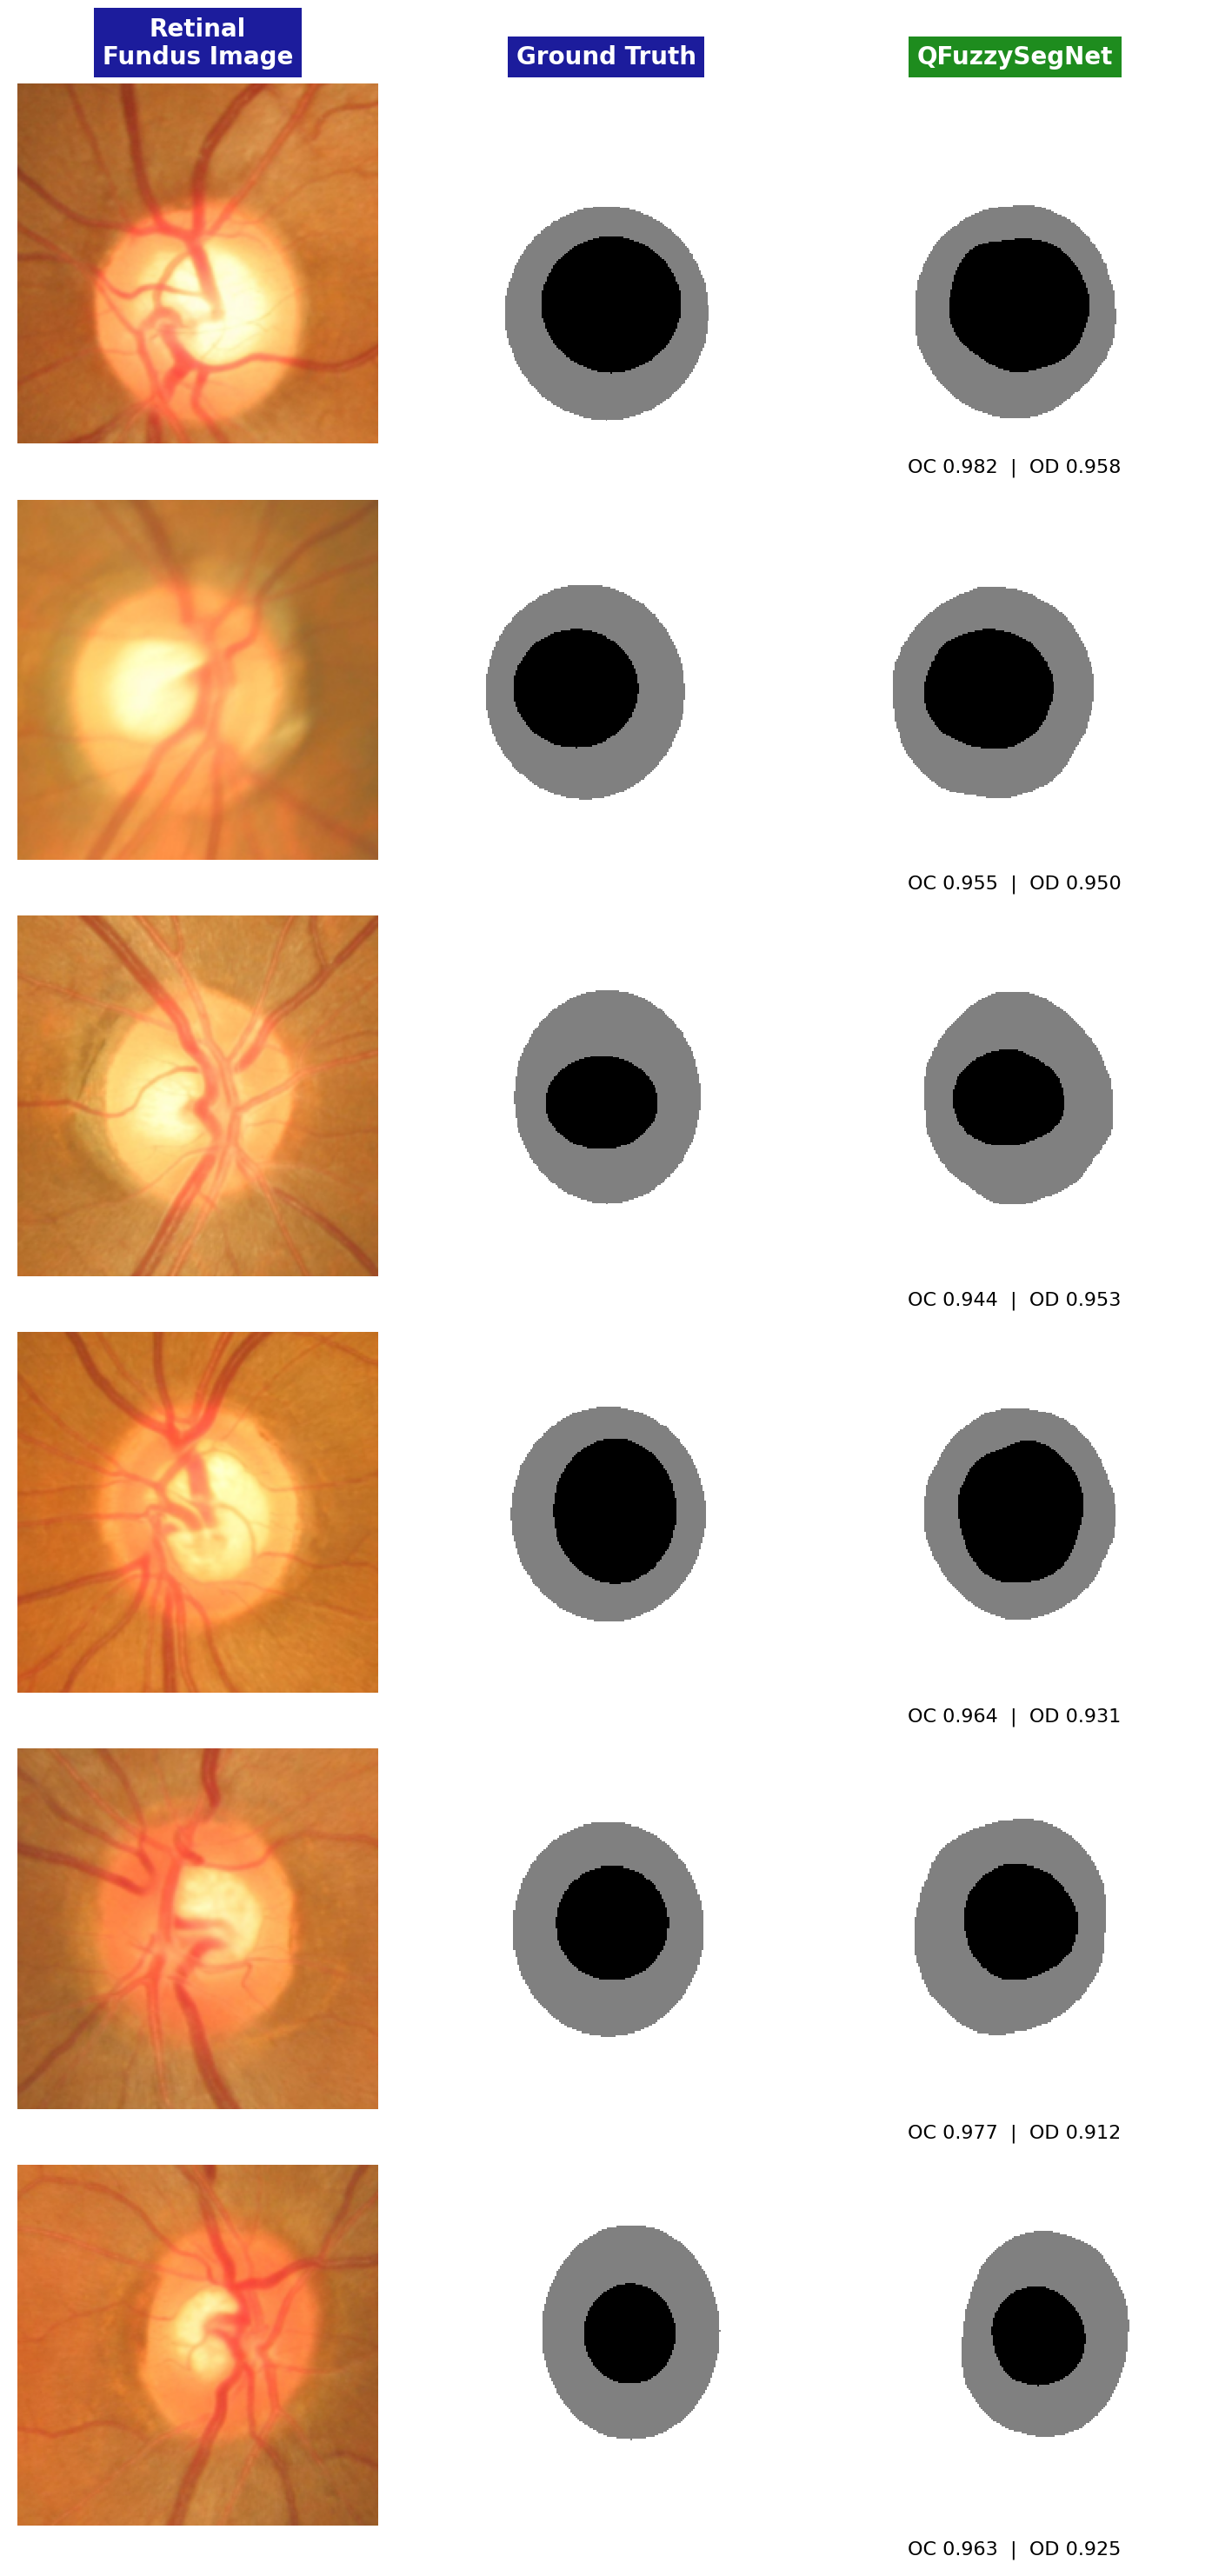

[np.int64(69),
 np.int64(109),
 np.int64(113),
 np.int64(105),
 np.int64(108),
 np.int64(55)]

In [14]:
# ----------------------------------------------------------------------------
# VISUALIZATION for the ORIGA script  (fundus image | ground truth | prediction)
#
# Paste this block into the ORIGA script ABOVE the "MAIN" section (or into a new
# notebook cell after the script has been run). It reuses: load_split, QFuzzySegNet,
# CFG, DEVICE, OUT_DIR, OC, OD, BG from that script.
# Colors: black = cup (OC), gray = disc (OD), white = background.
# ----------------------------------------------------------------------------
from matplotlib.colors import ListedColormap

MASK_CMAP = ListedColormap(["black", "#808080", "white"])   # 0=OC, 1=OD, 2=BG


@torch.no_grad()
def predict_all(model, X, batch_size=16):
    """uint8 images (N,H,W,3) -> predicted class maps (N,H,W)."""
    model.eval()
    out = []
    for i in range(0, len(X), batch_size):
        xb = torch.from_numpy(X[i:i + batch_size]).permute(0, 3, 1, 2).float() / 255.0
        out.append(model(xb.to(DEVICE)).argmax(1).cpu().numpy().astype(np.uint8))
    return np.concatenate(out)


def _dice(pm, tm):
    s = pm.sum() + tm.sum()
    return 1.0 if s == 0 else 2.0 * (pm & tm).sum() / s


def _disc_crop(mask, margin=0.35):
    """Square crop box (y0, y1, x0, x1) around the optic disc of a label map."""
    H, W = mask.shape
    ys, xs = np.where(mask != BG)
    if len(ys) == 0:
        return 0, H, 0, W
    cy, cx = (ys.min() + ys.max()) / 2, (xs.min() + xs.max()) / 2
    side = max(ys.max() - ys.min(), xs.max() - xs.min()) * (1 + 2 * margin)
    side = int(min(max(side, 32), H, W))
    y0 = int(np.clip(cy - side / 2, 0, H - side))
    x0 = int(np.clip(cx - side / 2, 0, W - side))
    return y0, y0 + side, x0, x0 + side


def visualize_predictions(model, X, Y, path, idx=None, n=4, select="even",
                          crop_to_disc=True, margin=0.35, show_scores=True,
                          pred_title="Prediction", dpi=200, seed=0):
    """
    idx          : explicit list of sample indices (overrides n / select)
    n            : number of rows
    select       : "even" | "random" | "best" | "worst"  (best/worst by mean OC/OD Dice)
    crop_to_disc : crop all three panels around the ground-truth disc (display only)
    """
    import matplotlib.pyplot as plt

    P = predict_all(model, X)
    dsc_oc = np.array([_dice(P[i] == OC, Y[i] == OC) for i in range(len(X))])
    dsc_od = np.array([_dice(P[i] == OD, Y[i] == OD) for i in range(len(X))])
    mean_dsc = (dsc_oc + dsc_od) / 2

    if idx is None:
        n = min(n, len(X))
        if select == "even":
            idx = np.linspace(0, len(X) - 1, n).astype(int)
        elif select == "random":
            idx = np.random.RandomState(seed).choice(len(X), n, replace=False)
        elif select == "best":
            idx = np.argsort(-mean_dsc)[:n]
        elif select == "worst":
            idx = np.argsort(mean_dsc)[:n]
        else:
            raise ValueError(select)
    idx = list(idx)
    n = len(idx)

    fig, axes = plt.subplots(n, 3, figsize=(7.2, 2.4 * n + 0.5), squeeze=False)
    heads = [("Retinal\nFundus Image", "#1c1c9c"),
             ("Ground Truth", "#1c1c9c"),
             (pred_title, "#1e8c1e")]

    for r, i in enumerate(idx):
        if crop_to_disc:
            y0, y1, x0, x1 = _disc_crop(Y[i], margin)
        else:
            y0, y1, x0, x1 = 0, Y[i].shape[0], 0, Y[i].shape[1]
        panels = [X[i][y0:y1, x0:x1], Y[i][y0:y1, x0:x1], P[i][y0:y1, x0:x1]]
        for c, panel in enumerate(panels):
            ax = axes[r, c]
            if c == 0:
                ax.imshow(panel)
            else:
                ax.imshow(panel, cmap=MASK_CMAP, vmin=0, vmax=2, interpolation="nearest")
            ax.axis("off")
            if r == 0:
                ax.set_title(heads[c][0], color="white", fontsize=10, fontweight="bold",
                             pad=8, bbox=dict(boxstyle="square,pad=0.35",
                                              fc=heads[c][1], ec="none"))
        if show_scores:
            axes[r, 2].text(0.5, -0.04, f"OC {dsc_oc[i]:.3f}  |  OD {dsc_od[i]:.3f}",
                            transform=axes[r, 2].transAxes, ha="center", va="top", fontsize=8)

    plt.tight_layout()
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    print("Saved:", path, "| samples:", idx)
    try:                                   # show inline in notebooks
        from IPython.display import display, Image as IPImage
        display(IPImage(filename=path))
    except Exception:
        pass
    return idx


def run_origa_visualization(n=4, select="even", pred_title="QFuzzySegNet"):
    """Load the best ORIGA checkpoint and visualize predictions on the ORIGA test split."""
    test_dir = Path("/kaggle/working/ORIGA_split") / "test"
    ckpt = os.path.join(OUT_DIR, "best_qfuzzy_seg_origa.pth")
    Xte, Yte = load_split(test_dir, CFG["img_size"], "test")

    model = QFuzzySegNet(dict(CFG, pretrained=False)).to(DEVICE)   # weights come from ckpt
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return visualize_predictions(
        model, Xte, Yte, os.path.join(OUT_DIR, "origa_visualization.png"),
        n=n, select=select, pred_title=pred_title)


# Usage:
#   run_origa_visualization()                       # 4 evenly spaced test samples
run_origa_visualization(n=6, select="best")     # 6 best cases
#   run_origa_visualization(n=6, select="worst")    # 6 worst cases
#
# To generate it automatically at the end of training, add this as the last line of main():
#   visualize_predictions(model, Xte, Yte, os.path.join(OUT_DIR, "origa_visualization.png"))

In [11]:
import os, re, math, random, time, json
from pathlib import Path
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models

# ----------------------------------------------------------------------------
# CONFIG  -- cross-dataset test: model trained on ORIGA, evaluated on Drishti-GS
#   Preprocessing is identical to training: 256x256, pixels rescaled to [0, 1].
#   Labels follow the paper encoding: 0 = OC, 1 = OD, 2 = background.
# ----------------------------------------------------------------------------
CFG = dict(
    img_size=256,
    batch_size=16,
    n_qubits=4,
    n_vqc_layers=3,
    n_fuzzy_mf=3,
    fpn_channels=64,
    num_classes=3,
    num_workers=0,
    seed=42,
)

TEST_DIR = "/kaggle/input/datasets/baivabmukherjee/fundus-images/Drishti_GS/test"
CKPT_NAME = "best_qfuzzy_seg_origa.pth"
CKPT_CANDIDATES = [
    f"/kaggle/working/{CKPT_NAME}",
    f"./{CKPT_NAME}",
]

OC, OD, BG = 0, 1, 2
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."


def seed_everything(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)


# ----------------------------------------------------------------------------
# DATA DISCOVERY (robust to different folder layouts)
# ----------------------------------------------------------------------------
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
MASK_KEYS = ("mask", "gt", "label", "annot", "seg", "ground")


def print_tree(root, max_files=6):
    for dp, dn, fn in os.walk(root):
        depth = dp[len(str(root)):].count(os.sep)
        if depth > 3:
            continue
        print("  " * depth + os.path.basename(dp) + "/")
        for f in sorted(fn)[:max_files]:
            print("  " * (depth + 1) + f)
        if len(fn) > max_files:
            print("  " * (depth + 1) + f"... (+{len(fn) - max_files} files)")


def is_mask_path(rel):
    parts = rel.lower().replace("\\", "/").split("/")
    return any(k in p for p in parts for k in MASK_KEYS)


def norm_stem(fn):
    s = os.path.splitext(fn)[0].lower()
    return re.sub(r"[_\-]?(mask|gt|seg|segmentation|label|annotation|annot)$", "", s)


def collect_pairs(split_dir):
    """Uses index.json if present, otherwise matches images and masks by file stem."""
    split_dir = Path(split_dir)
    index_file = split_dir / "index.json"
    if index_file.is_file():
        with open(index_file) as f:
            records = json.load(f)
        pairs = [(str(split_dir / r["image"]), str(split_dir / r["mask"])) for r in records]
        bad = [p for p in pairs if not (os.path.isfile(p[0]) and os.path.isfile(p[1]))]
        if bad:
            raise FileNotFoundError(f"{len(bad)} indexed pairs missing files. First: {bad[0]}")
        return pairs

    imgs, msks = {}, {}
    for dp, _, fns in os.walk(split_dir):
        for fn in sorted(fns):
            if os.path.splitext(fn)[1].lower() not in IMG_EXT:
                continue
            full = os.path.join(dp, fn)
            rel = os.path.relpath(full, split_dir)
            key = norm_stem(fn)
            if is_mask_path(rel):
                if key in msks:
                    print(f"  [warn] duplicate mask for '{key}', keeping {msks[key]}")
                    continue
                msks[key] = full
            else:
                imgs[key] = full

    keys = sorted(set(imgs) & set(msks))
    print(f"images found: {len(imgs)}, masks found: {len(msks)}, matched pairs: {len(keys)}")
    if not keys:
        print_tree(split_dir)
        raise RuntimeError("No image-mask pairs matched. Check the folder tree above.")
    unmatched = sorted(set(imgs) ^ set(msks))
    if unmatched:
        print(f"  [warn] {len(unmatched)} unmatched stems, e.g. {unmatched[:3]}")
    return [(imgs[k], msks[k]) for k in keys]


def load_raw_masks(pairs, size):
    """Load masks resized with NEAREST, kept as raw values (no class mapping yet)."""
    raw = []
    for _, mp in pairs:
        m = np.array(Image.open(mp))
        if m.ndim == 3:
            m = m[..., 0]
        m = np.array(Image.fromarray(m).resize((size, size), Image.NEAREST))
        raw.append(m)
    return np.stack(raw)


def map_masks_auto(raw):
    """Map raw mask values to the paper encoding (0=OC, 1=OD, 2=BG) automatically.

    Works for 0/128/255 masks and for {0,1,2} id masks, in either direction:
      - the middle value is always the optic disc ring;
      - of the two extreme values, the one covering more pixels is background,
        the other one is the cup.
    """
    raw = raw.copy()
    if raw.max() > 2:                     # grayscale-coded: snap to {0, 128, 255}
        snapped = np.zeros_like(raw)
        snapped[raw >= 64] = 128
        snapped[raw >= 192] = 255
        raw = snapped
    vals = np.unique(raw)
    print("  raw mask values:", vals.tolist())
    if len(vals) == 3:
        lo, mid, hi = vals
        n_lo, n_hi = (raw == lo).sum(), (raw == hi).sum()
        bg_val, oc_val = (lo, hi) if n_lo > n_hi else (hi, lo)
        out = np.full(raw.shape, BG, np.uint8)
        out[raw == mid] = OD
        out[raw == oc_val] = OC
        out[raw == bg_val] = BG
        print(f"  mapping: background={bg_val}, disc={mid}, cup={oc_val}")
        return out
    raise ValueError(
        f"Expected 3 distinct mask values (cup / disc / background) but found {vals.tolist()}.\n"
        "If this dataset stores cup and disc as separate binary masks, they must be merged first."
    )


def load_split(split_dir, size, name):
    pairs = collect_pairs(split_dir)
    print(f"[{name}] image-mask pairs: {len(pairs)}")
    X = np.zeros((len(pairs), size, size, 3), np.uint8)
    for i, (ip, _) in enumerate(tqdm(pairs, desc=f"loading {name}")):
        X[i] = np.array(Image.open(ip).convert("RGB").resize((size, size), Image.BILINEAR))
    Y = map_masks_auto(load_raw_masks(pairs, size))
    print(f"[{name}] class pixel fractions (OC/OD/BG):",
          np.round(np.bincount(Y.ravel(), minlength=3) / Y.size, 4))
    return X, Y


class FundusDS(Dataset):
    """Same preprocessing as training: resize (done at load) + rescale to [0, 1]."""

    def __init__(self, X, Y):
        self.X, self.Y = X, Y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        img = torch.from_numpy(self.X[i]).permute(2, 0, 1).float() / 255.0
        msk = torch.from_numpy(self.Y[i]).long()
        return img, msk


# ----------------------------------------------------------------------------
# MODEL (identical to the training script)
# ----------------------------------------------------------------------------
def _ry_mat(theta):
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)


def _cnot_ring_inv_perm(n):
    inv = [0] * (2 ** n)
    for b in range(2 ** n):
        bits = [(b >> (n - 1 - w)) & 1 for w in range(n)]
        for c in range(n):
            t = (c + 1) % n
            if bits[c]:
                bits[t] ^= 1
        nb = sum(bit << (n - 1 - w) for w, bit in enumerate(bits))
        inv[nb] = b
    return torch.tensor(inv, dtype=torch.long)


class VQC(nn.Module):
    def __init__(self, n_qubits=4, n_layers=3):
        super().__init__()
        self.n, self.L = n_qubits, n_layers
        self.weights = nn.Parameter(torch.randn(n_layers, n_qubits) * 0.3)
        self.register_buffer("inv_perm", _cnot_ring_inv_perm(n_qubits))
        z = torch.tensor([[1 - 2 * ((b >> (n_qubits - 1 - w)) & 1) for w in range(n_qubits)]
                          for b in range(2 ** n_qubits)], dtype=torch.float32)
        self.register_buffer("zsign", z)

    def _apply_1q(self, state, mats, w):
        N = state.shape[0]
        s = state.view(N, 2 ** w, 2, 2 ** (self.n - w - 1))
        if mats.dim() == 3:
            s = torch.einsum("nij,najb->naib", mats, s)
        else:
            s = torch.einsum("ij,najb->naib", mats, s)
        return s.reshape(N, -1)

    def forward(self, x):
        N = x.shape[0]
        state = x.new_zeros(N, 2 ** self.n)
        state[:, 0] = 1.0
        for l in range(self.L):
            for w in range(self.n):
                state = self._apply_1q(state, _ry_mat(x[:, w]), w)
            for w in range(self.n):
                state = self._apply_1q(state, _ry_mat(self.weights[l, w]), w)
            state = state[:, self.inv_perm]
        return (state ** 2) @ self.zsign


class QuantumFuzzy(nn.Module):
    def __init__(self, n_in, n_mf, out_ch):
        super().__init__()
        self.n_in, self.n_mf = n_in, n_mf
        self.centers = nn.Parameter(torch.linspace(-1, 1, n_mf).repeat(n_in, 1))
        self.log_sigma = nn.Parameter(torch.full((n_in, n_mf), math.log(0.6)))
        self.consequent = nn.Linear(n_mf ** n_in, out_ch)

    def forward(self, q):
        d = q.unsqueeze(-1) - self.centers
        mu = torch.exp(-0.5 * (d / self.log_sigma.exp()) ** 2)
        f = mu[:, 0]
        for i in range(1, self.n_in):
            f = (f.unsqueeze(-1) * mu[:, i].unsqueeze(1)).flatten(1)
        f = f / (f.sum(1, keepdim=True) + 1e-8)
        return self.consequent(f)


class QuantumFuzzyBlock(nn.Module):
    def __init__(self, in_ch, out_ch, n_qubits, n_layers, n_mf):
        super().__init__()
        self.nq = n_qubits
        self.to_angles = nn.Sequential(nn.Conv2d(in_ch, n_qubits, 1), nn.BatchNorm2d(n_qubits))
        self.vqc = VQC(n_qubits, n_layers)
        self.fuzzy = QuantumFuzzy(n_qubits, n_mf, out_ch)
        self.out_ch = out_ch

    def forward(self, x):
        B, _, H, W = x.shape
        a = torch.tanh(self.to_angles(x)) * math.pi
        tok = a.permute(0, 2, 3, 1).reshape(-1, self.nq)
        q = self.vqc(tok.float())
        y = self.fuzzy(q)
        return y.view(B, H, W, self.out_ch).permute(0, 3, 1, 2)


def cbr(i, o, k=3):
    return nn.Sequential(nn.Conv2d(i, o, k, padding=k // 2, bias=False),
                         nn.BatchNorm2d(o), nn.ReLU(inplace=True))


class MobileNetV3SmallBackbone(nn.Module):
    out_channels = [16, 24, 48, 576]

    def __init__(self, pretrained=False):
        super().__init__()
        # weights come from the ORIGA checkpoint, so no ImageNet download is needed
        m = models.mobilenet_v3_small(weights=None)
        f = m.features
        self.s1, self.s2, self.s3, self.s4 = f[:2], f[2:4], f[4:9], f[9:]

    def forward(self, x):
        c1 = self.s1(x); c2 = self.s2(c1); c3 = self.s3(c2); c4 = self.s4(c3)
        return [c1, c2, c3, c4]


class MultiScaleFPN(nn.Module):
    def __init__(self, in_chs, ch):
        super().__init__()
        self.lat = nn.ModuleList([nn.Conv2d(c, ch, 1) for c in in_chs])
        self.smooth = nn.ModuleList([cbr(ch, ch, 3) for _ in in_chs])

    def forward(self, feats):
        lat = [l(f) for l, f in zip(self.lat, feats)]
        for i in range(len(lat) - 1, 0, -1):
            lat[i - 1] = lat[i - 1] + F.interpolate(lat[i], size=lat[i - 1].shape[-2:],
                                                    mode="bilinear", align_corners=False)
        return [s(l) for s, l in zip(self.smooth, lat)]


class QFuzzySegNet(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        ch = cfg["fpn_channels"]
        self.backbone = MobileNetV3SmallBackbone(False)
        self.fpn = MultiScaleFPN(self.backbone.out_channels, ch)
        self.ms_fuse = cbr(ch * 4, ch, 3)
        self.qf = QuantumFuzzyBlock(ch, ch, cfg["n_qubits"], cfg["n_vqc_layers"], cfg["n_fuzzy_mf"])
        self.qf_bn = nn.Sequential(nn.BatchNorm2d(ch), nn.ReLU(inplace=True))
        self.decoder = nn.Sequential(cbr(ch * 2, ch, 3), cbr(ch, ch, 3))
        self.head = nn.Conv2d(ch, cfg["num_classes"], 1)

    def forward(self, x):
        H, W = x.shape[-2:]
        p1, p2, p3, p4 = self.fpn(self.backbone(x))
        sz = p1.shape[-2:]
        up = lambda t: F.interpolate(t, size=sz, mode="bilinear", align_corners=False)
        fused = self.ms_fuse(torch.cat([p1, up(p2), up(p3), up(p4)], 1))
        q = self.qf_bn(self.qf(p3))
        out = self.decoder(torch.cat([fused, up(q)], 1))
        logits = self.head(out)
        return F.interpolate(logits, size=(H, W), mode="bilinear", align_corners=False)


# ----------------------------------------------------------------------------
# METRICS (paper Eqs. 8-11), per class OC / OD
# ----------------------------------------------------------------------------
def class_metrics(pm, tm):
    tp = (pm & tm).sum().item()
    fp = (pm & ~tm).sum().item()
    fn = (~pm & tm).sum().item()
    if tp + fp + fn == 0:
        return dict(p=1.0, r=1.0, dsc=1.0, iou=1.0)
    return dict(
        p=tp / (tp + fp) if tp + fp else 0.0,
        r=tp / (tp + fn) if tp + fn else 0.0,
        dsc=2 * tp / (2 * tp + fp + fn),
        iou=tp / (tp + fp + fn),
    )


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    acc = {c: {"p": [], "r": [], "dsc": [], "iou": []} for c in ("oc", "od")}
    for x, y in loader:
        pred = model(x.to(DEVICE)).argmax(1).cpu()
        for p, t in zip(pred, y):
            for name, cid in (("oc", OC), ("od", OD)):
                m = class_metrics(p == cid, t == cid)
                for k in m:
                    acc[name][k].append(m[k])
    r = {}
    for name in ("oc", "od"):
        r[f"dsc_{name}"] = float(np.mean(acc[name]["dsc"]))
        r[f"iou_{name}"] = float(np.mean(acc[name]["iou"]))
        r[f"precision_{name}"] = float(np.mean(acc[name]["p"]))
        r[f"recall_{name}"] = float(np.mean(acc[name]["r"]))
    r["precision"] = (r["precision_oc"] + r["precision_od"]) / 2
    r["recall"] = (r["recall_oc"] + r["recall_od"]) / 2
    r["mean_dsc"] = (r["dsc_oc"] + r["dsc_od"]) / 2
    r["mean_iou"] = (r["iou_oc"] + r["iou_od"]) / 2
    return r


@torch.no_grad()
def save_predictions(model, X, Y, path, n=6):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    model.eval()
    idx = np.linspace(0, len(X) - 1, min(n, len(X))).astype(int)
    fig, ax = plt.subplots(3, len(idx), figsize=(3 * len(idx), 9))
    ax = np.atleast_2d(ax).reshape(3, -1)
    for j, i in enumerate(idx):
        img = torch.from_numpy(X[i]).permute(2, 0, 1).float() / 255
        pred = model(img.unsqueeze(0).to(DEVICE)).argmax(1)[0].cpu().numpy()
        ax[0, j].imshow(X[i]); ax[1, j].imshow(Y[i], vmin=0, vmax=2, cmap="gray")
        ax[2, j].imshow(pred, vmin=0, vmax=2, cmap="gray")
        for k in range(3): ax[k, j].axis("off")
    ax[0, 0].set_title("image"); ax[1, 0].set_title("ground truth"); ax[2, 0].set_title("prediction")
    plt.tight_layout(); plt.savefig(path, dpi=110); plt.close()


# ----------------------------------------------------------------------------
# MAIN
# ----------------------------------------------------------------------------
def find_checkpoint():
    for c in CKPT_CANDIDATES:
        if os.path.isfile(c):
            return c
    for root in ("/kaggle/input", "/kaggle/working"):       # search attached datasets too
        if os.path.isdir(root):
            for dp, _, fns in os.walk(root):
                if CKPT_NAME in fns:
                    return os.path.join(dp, CKPT_NAME)
    raise FileNotFoundError(
        f"Could not find '{CKPT_NAME}'. Train on ORIGA first or set CKPT_CANDIDATES to its path.")


def main():
    seed_everything(CFG["seed"])

    if not os.path.isdir(TEST_DIR):
        raise FileNotFoundError(f"Test directory not found: {TEST_DIR}")
    print("Test folder layout:")
    print_tree(TEST_DIR)

    S = CFG["img_size"]
    Xte, Yte = load_split(TEST_DIR, S, "drishti-test")

    te_loader = DataLoader(FundusDS(Xte, Yte), batch_size=CFG["batch_size"], shuffle=False,
                           num_workers=CFG["num_workers"], pin_memory=(DEVICE.type == "cuda"))

    model = QFuzzySegNet(CFG).to(DEVICE)
    ckpt = find_checkpoint()
    print("Loading checkpoint:", ckpt)
    state = torch.load(ckpt, map_location=DEVICE)
    model.load_state_dict(state)
    model.eval()

    t0 = time.time()
    metrics = evaluate(model, te_loader)
    print(f"\nORIGA-trained model on Drishti-GS test ({len(Xte)} images, {time.time() - t0:.0f}s)")
    for k, v in metrics.items():
        print(f"  {k:14s}: {v:.4f}")

    out_json = os.path.join(OUT_DIR, "drishti_test_metrics.json")
    with open(out_json, "w") as f:
        json.dump(metrics, f, indent=2)

    pred_path = os.path.join(OUT_DIR, "drishti_test_predictions.png")
    save_predictions(model, Xte, Yte, pred_path)
    print("\nMetrics:", out_json, "\nPredictions:", pred_path)


if __name__ == "__main__":
    main()

Test folder layout:
test/
  image/
    gdrishtiGS_001.png
    gdrishtiGS_003.png
    gdrishtiGS_005.png
    gdrishtiGS_006.png
    gdrishtiGS_011.png
    gdrishtiGS_014.png
    ... (+45 files)
  mask/
    gdrishtiGS_001.png
    gdrishtiGS_003.png
    gdrishtiGS_005.png
    gdrishtiGS_006.png
    gdrishtiGS_011.png
    gdrishtiGS_014.png
    ... (+45 files)
images found: 51, masks found: 51, matched pairs: 51
[drishti-test] image-mask pairs: 51


loading drishti-test:   0%|          | 0/51 [00:00<?, ?it/s]

  raw mask values: [0, 128, 255]
  mapping: background=255, disc=128, cup=0
[drishti-test] class pixel fractions (OC/OD/BG): [0.0748 0.0911 0.8341]
Loading checkpoint: /kaggle/working/best_qfuzzy_seg_origa.pth

ORIGA-trained model on Drishti-GS test (51 images, 0s)
  dsc_oc        : 0.8405
  iou_oc        : 0.7438
  precision_oc  : 0.8532
  recall_oc     : 0.8859
  dsc_od        : 0.7903
  iou_od        : 0.6623
  precision_od  : 0.8325
  recall_od     : 0.7746
  precision     : 0.8429
  recall        : 0.8302
  mean_dsc      : 0.8154
  mean_iou      : 0.7031

Metrics: /kaggle/working/drishti_test_metrics.json 
Predictions: /kaggle/working/drishti_test_predictions.png


images found: 51, masks found: 51, matched pairs: 51
[drishti-test] image-mask pairs: 51


loading drishti-test:   0%|          | 0/51 [00:00<?, ?it/s]

  raw mask values: [0, 128, 255]
  mapping: background=255, disc=128, cup=0
[drishti-test] class pixel fractions (OC/OD/BG): [0.0748 0.0911 0.8341]
Saved: /kaggle/working/drishti_visualization.png | samples: [np.int64(43), np.int64(11), np.int64(35), np.int64(15), np.int64(37), np.int64(29)]


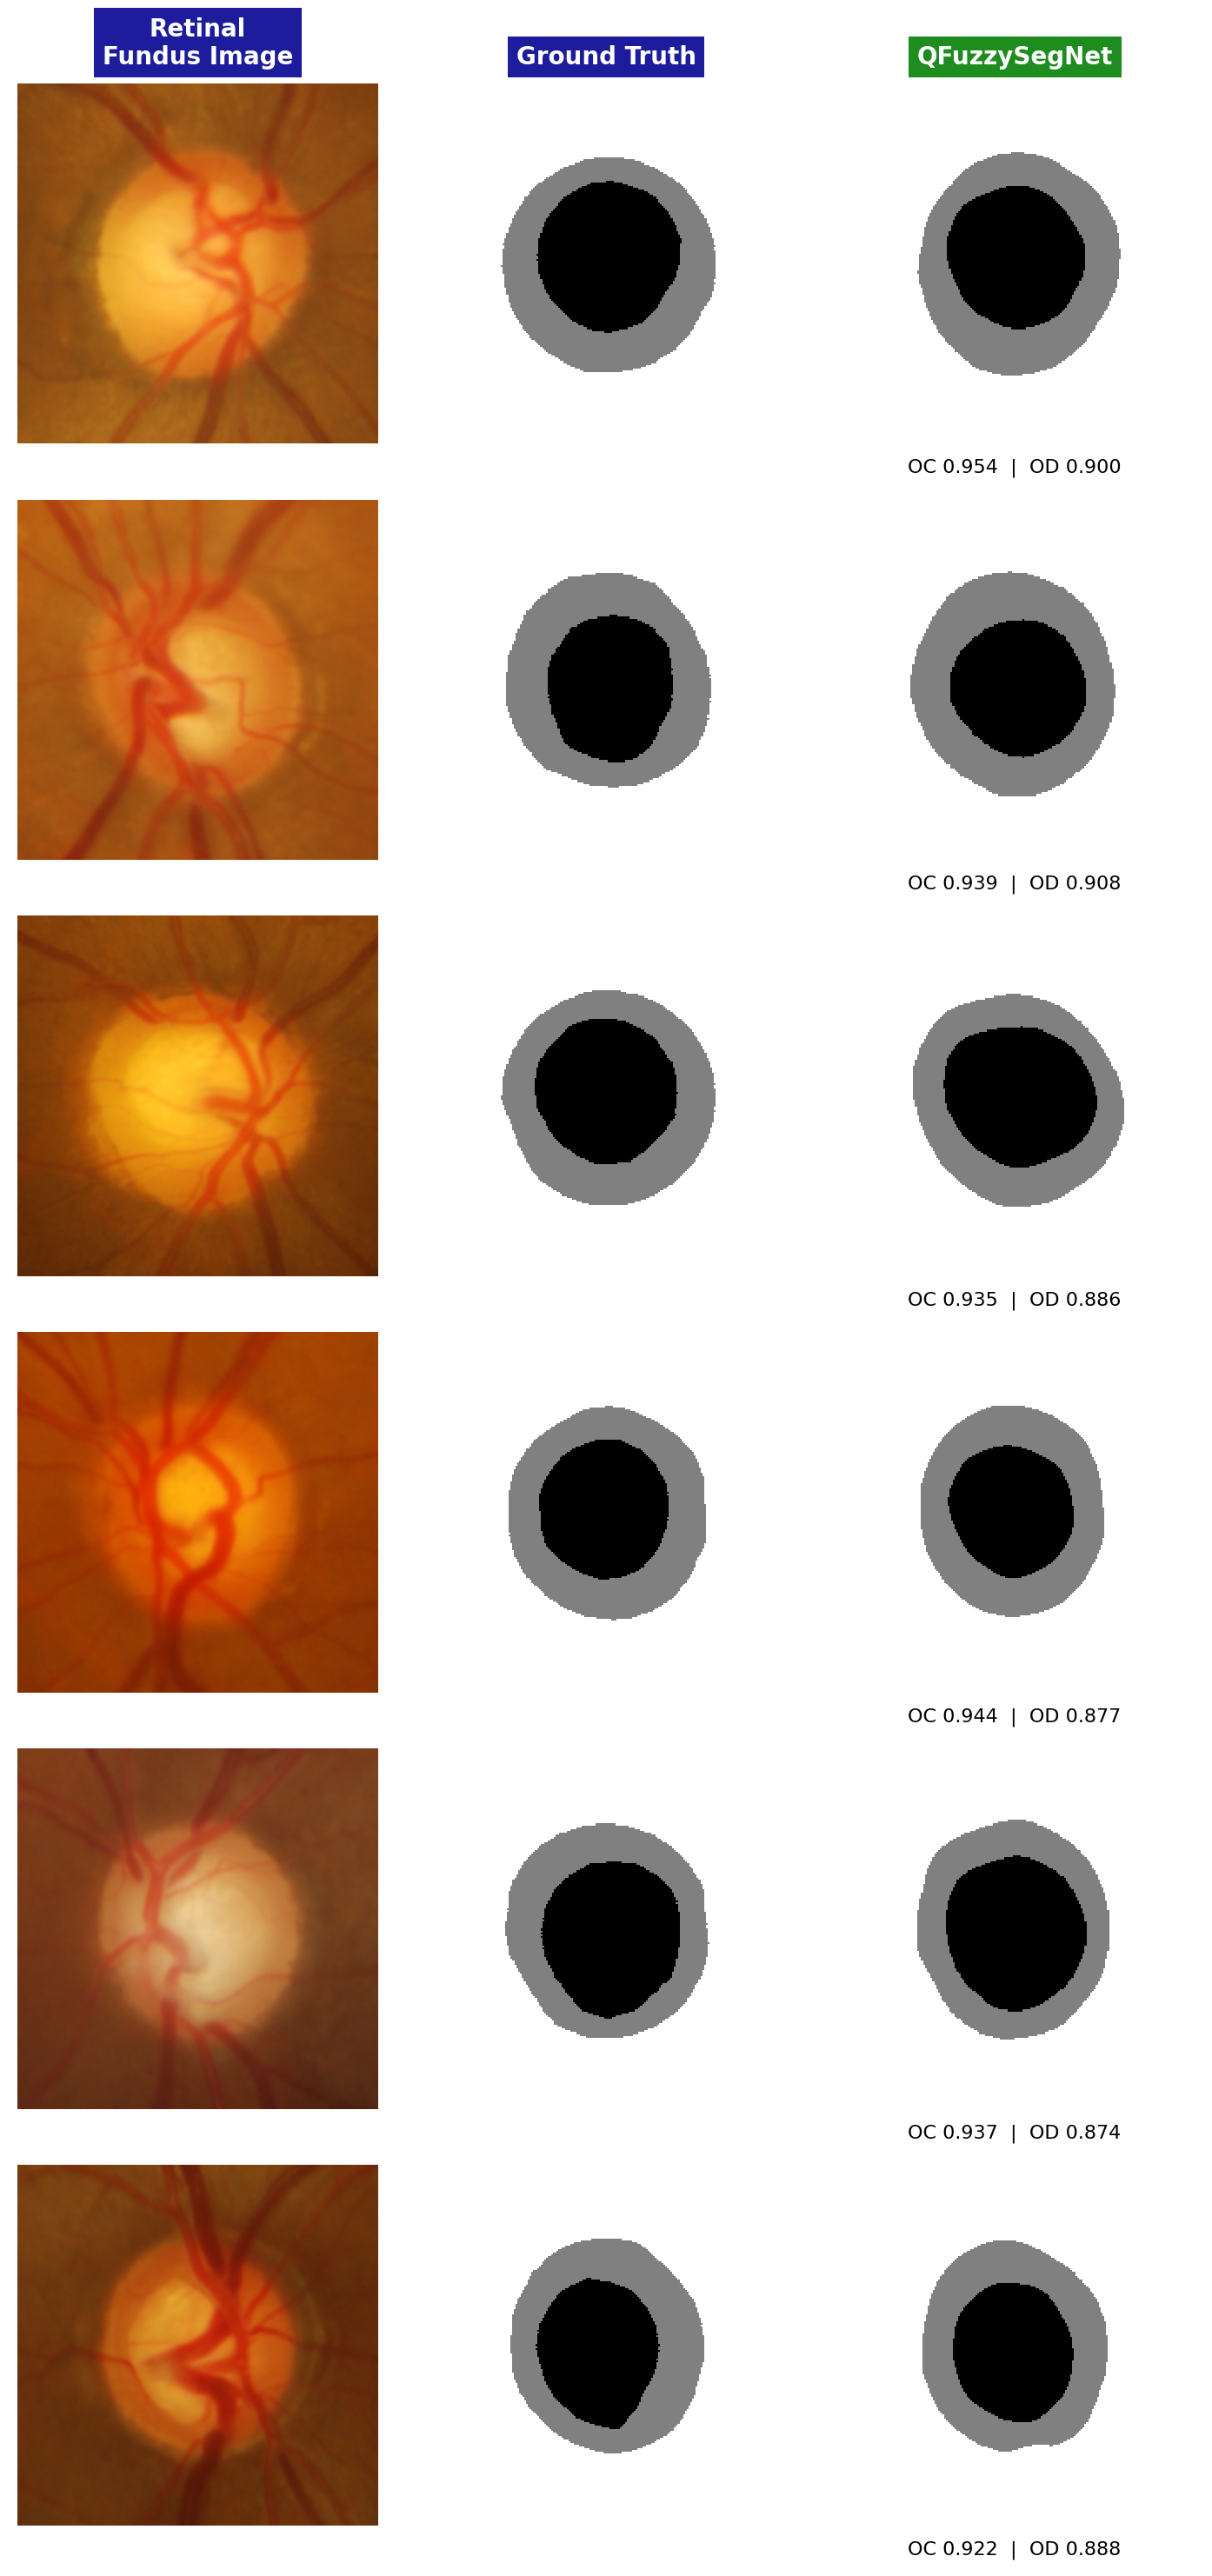

[np.int64(43),
 np.int64(11),
 np.int64(35),
 np.int64(15),
 np.int64(37),
 np.int64(29)]

In [13]:
# ----------------------------------------------------------------------------
# VISUALIZATION  (fundus image | ground truth | prediction), as in the CSP-SegNet figure
#
# Run this AFTER the test script's definitions are in memory (same notebook /
# same file): it reuses load_split, QFuzzySegNet, find_checkpoint, CFG, TEST_DIR,
# DEVICE, OUT_DIR, OC, OD, BG.  Colors: black = cup, gray = disc, white = background.
# ----------------------------------------------------------------------------
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

MASK_CMAP = ListedColormap(["black", "#808080", "white"])   # 0=OC, 1=OD, 2=BG


@torch.no_grad()
def predict_all(model, X, batch_size=16):
    """Run the model on a uint8 image array (N,H,W,3) -> predicted class map (N,H,W)."""
    model.eval()
    out = []
    for i in range(0, len(X), batch_size):
        xb = torch.from_numpy(X[i:i + batch_size]).permute(0, 3, 1, 2).float() / 255.0
        out.append(model(xb.to(DEVICE)).argmax(1).cpu().numpy().astype(np.uint8))
    return np.concatenate(out)


def _dice(pm, tm):
    s = pm.sum() + tm.sum()
    return 1.0 if s == 0 else 2.0 * (pm & tm).sum() / s


def _disc_crop(mask, margin=0.35):
    """Square crop box (y0, y1, x0, x1) around the optic disc of a label map."""
    H, W = mask.shape
    ys, xs = np.where(mask != BG)
    if len(ys) == 0:
        return 0, H, 0, W
    cy, cx = (ys.min() + ys.max()) / 2, (xs.min() + xs.max()) / 2
    side = max(ys.max() - ys.min(), xs.max() - xs.min()) * (1 + 2 * margin)
    side = int(min(max(side, 32), H, W))
    y0 = int(np.clip(cy - side / 2, 0, H - side))
    x0 = int(np.clip(cx - side / 2, 0, W - side))
    return y0, y0 + side, x0, x0 + side


def visualize_predictions(model, X, Y, path, idx=None, n=4, select="even",
                          crop_to_disc=True, margin=0.35, show_scores=True,
                          pred_title="Prediction", dpi=200, seed=0):
    """
    idx          : explicit list of sample indices (overrides n / select)
    n            : number of rows
    select       : "even" | "random" | "best" | "worst"   (best/worst by mean OC/OD Dice)
    crop_to_disc : crop all three panels around the ground-truth disc (display only)
    """
    P = predict_all(model, X)
    dsc_oc = np.array([_dice(P[i] == OC, Y[i] == OC) for i in range(len(X))])
    dsc_od = np.array([_dice(P[i] == OD, Y[i] == OD) for i in range(len(X))])
    mean_dsc = (dsc_oc + dsc_od) / 2

    if idx is None:
        n = min(n, len(X))
        if select == "even":
            idx = np.linspace(0, len(X) - 1, n).astype(int)
        elif select == "random":
            idx = np.random.RandomState(seed).choice(len(X), n, replace=False)
        elif select == "best":
            idx = np.argsort(-mean_dsc)[:n]
        elif select == "worst":
            idx = np.argsort(mean_dsc)[:n]
        else:
            raise ValueError(select)
    idx = list(idx)
    n = len(idx)

    fig, axes = plt.subplots(n, 3, figsize=(7.2, 2.4 * n + 0.5), squeeze=False)
    heads = [("Retinal\nFundus Image", "#1c1c9c"),
             ("Ground Truth", "#1c1c9c"),
             (pred_title, "#1e8c1e")]

    for r, i in enumerate(idx):
        if crop_to_disc:
            y0, y1, x0, x1 = _disc_crop(Y[i], margin)
        else:
            y0, y1, x0, x1 = 0, Y[i].shape[0], 0, Y[i].shape[1]
        panels = [X[i][y0:y1, x0:x1],
                  Y[i][y0:y1, x0:x1],
                  P[i][y0:y1, x0:x1]]
        for c, panel in enumerate(panels):
            ax = axes[r, c]
            if c == 0:
                ax.imshow(panel)
            else:
                ax.imshow(panel, cmap=MASK_CMAP, vmin=0, vmax=2, interpolation="nearest")
            ax.axis("off")
            if r == 0:
                ax.set_title(heads[c][0], color="white", fontsize=10, fontweight="bold",
                             pad=8, bbox=dict(boxstyle="square,pad=0.35",
                                              fc=heads[c][1], ec="none"))
        if show_scores:
            axes[r, 2].text(0.5, -0.04, f"OC {dsc_oc[i]:.3f}  |  OD {dsc_od[i]:.3f}",
                            transform=axes[r, 2].transAxes, ha="center", va="top", fontsize=8)

    plt.tight_layout()
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    print("Saved:", path, "| samples:", idx)
    try:                                   # show inline in notebooks
        from IPython.display import display, Image as IPImage
        display(IPImage(filename=path))
    except Exception:
        pass
    return idx


def run_visualization(n=4, select="even", pred_title="QFuzzySegNet"):
    Xte, Yte = load_split(TEST_DIR, CFG["img_size"], "drishti-test")
    model = QFuzzySegNet(CFG).to(DEVICE)
    model.load_state_dict(torch.load(find_checkpoint(), map_location=DEVICE))
    return visualize_predictions(
        model, Xte, Yte, os.path.join(OUT_DIR, "drishti_visualization.png"),
        n=n, select=select, pred_title=pred_title)


# Usage (after the test script's code has been run in the notebook):
#run_visualization()                          # 4 evenly spaced samples
run_visualization(n=6, select="best")        # 6 best cases
#   run_visualization(n=6, select="worst")       # 6 worst cases
#   visualize_predictions(model, Xte, Yte, "out.png", idx=[0, 5, 12, 20])